# Synthetic Reading of Ruskin Bond's "The Eyes Have It"
### Sight, blindness and the conversation of concealment

**Simanta Nandi**, MA, Digital Humanities and Social Sciences, Indian Institute of Technology (ISM) Dhanbad<br>
**Project supervision:** [Shanmugapriya T](https://shanmugapriya.com/) and [Sourav Ghosh](https://linktr.ee/sourav.dh.litcult)<br>
**Contact:** [25ma0013@iitism.ac.in](mailto:25ma0013@iitism.ac.in) · [about.me/simantanandi](https://about.me/simantanandi)<br>
**Licence:** [CC BY-NC 4.0](https://creativecommons.org/licenses/by-nc/4.0/). "The Eyes Have It" © Ruskin Bond is not covered by this licence.

---

**Research questions**

1. What is the metaphor of sight and blindness across the full story?
2. How do linguistic markers of evasion, assumption and conversational turn-taking reveal the underlying information asymmetry and mutual deception between the narrator and the girl?

**Method.** This notebook follows the *synthetic reading* method of Ghosh, Shanmugapriya T and Mandal (2026), in which interpretation comes before computation:

| Step of the method | Section of this notebook |
|---|---|
| 1. Partial reading | Step 1 |
| 2. Initial impression | Step 2 |
| 3. Text upload and preparation | Step 1 (upload) and Step 3 (checking the text) |
| 4. Query generation | Step 4 (the prompt) |
| 5. Targeted extraction | Step 5 (Ollama, verification, lexicon) |
| 6. Computation and visualisation | Step 6 |
| 7. Interpretation | Step 7, and the report pages in Step 8 |

**How to run it.** Choose **Runtime → Change runtime type → T4 GPU**, then **Runtime → Run all**. When Step 1 asks for a file, upload the cleaned corpus `corpus_the_eyes_have_it.txt` (the same file as before). Step 5 downloads and runs the model, which takes about 10 minutes in all. At the end, a zip file with every result downloads.

**Copyright.** The story is in copyright. Its text is kept only in the private files `corpus/`, `partial_reading/partial_reading.txt` and `extraction/passages/`. Cells marked 🔒 print story sentences, so Step 9 makes a public copy of this notebook with those outputs removed. Upload only the public copy and the zip contents to GitHub.

## Setup

**What this does.** It creates the folders the project writes to and installs the three libraries that Colab does not always have up to date.

| Folder | What goes in it |
|---|---|
| `corpus/` | the story (private) |
| `partial_reading/` | the sentences read in Step 1 (private) and their numbers (public) |
| `prompt/` | the prompt sent to the model |
| `extraction/` | the model's answer, the verification and the lexicon |
| `figures/` | every figure as a JPG image and as an interactive HTML file |
| `docs/` | the interpretation and the report pages |

In [1]:
import os, json
for folder in ["corpus", "partial_reading", "prompt", "extraction", "extraction/passages", "figures", "docs"]:
    os.makedirs(folder, exist_ok=True)

!pip install -q plotly scipy pandas
print("Setup done")

Setup done


## Step 1. Partial reading 🔒

**What I am doing.** Synthetic reading begins with a deliberately partial reading, so that my first impression is formed before I know the whole story.

1. The story is loaded from `corpus/the_eyes_have_it.txt`. If the file is not there, Colab asks me to upload it. Its SHA-256 fingerprint is checked against the corpus used throughout the project, so I know the text has not changed.
2. The story is split into sentences. A reporting tag that follows a question or an exclamation (for example *"…Dehra? I asked."*) stays in the same sentence. The story has **99 sentences** in **40 paragraphs**; the title and the byline are not counted.
3. The sentences are divided into **three equal parts of 33 sentences**. From each part I read about one-fifth (20%), that is, **7 sentences**:
   - **Part 1, the beginning:** the first 7 sentences;
   - **Part 2, the middle:** 7 sentences chosen at random (seed 42, so the choice is the same every time);
   - **Part 3, the end:** the last 7 sentences.

These are the same three parts and the same 21 sentences as in the earlier version of the project.

🔒 *The output of this cell shows story sentences. It is removed from the public copy made in Step 9.*

In [ ]:
# 🔒 PRIVATE-OUTPUT
import re, random, hashlib

STORY_PATH = "corpus/the_eyes_have_it.txt"
EXPECTED_SHA256 = "375813bd45f1877460407da395735933da48d6bf42e8da9d53a1c6929abbceb4"
TITLE_LINES = ["The Eyes Have It", "by Ruskin Bond"]

def load_story():
    """Use corpus/the_eyes_have_it.txt if it exists; otherwise ask for an upload (Colab)."""
    if not os.path.exists(STORY_PATH):
        from google.colab import files
        print("Upload corpus_the_eyes_have_it.txt now.")
        uploaded = files.upload()
        name = next(iter(uploaded))
        with open(STORY_PATH, "wb") as f:
            f.write(uploaded[name])
    return open(STORY_PATH, encoding="utf-8").read()

raw_story = load_story()
sha = hashlib.sha256(open(STORY_PATH, "rb").read()).hexdigest()
print("SHA-256:", sha[:16] + "…", "(same corpus as before)" if sha == EXPECTED_SHA256 else
      "WARNING: this is not the corpus used before; the counts and the essay will differ.")

SPLIT = re.compile(r"(?:(?<=[.!?])|(?<=[.!?][”’\"']))\s+(?=[“‘\"'A-Z0-9$])")
TAG = re.compile(r"^(I|He|She|They|We)\s+(asked|said|replied|remarked|ventured|answered)\b")

def story_paragraphs(text):
    paras_ = [re.sub(r"\s*\n\s*", " ", p).strip() for p in re.split(r"\n\s*\n", text) if p.strip()]
    return [p for p in paras_ if p not in TITLE_LINES]

def split_sentences(paragraphs):
    """(paragraph number, sentence) pairs; a reporting tag stays with the speech before it."""
    out = []
    for pi, para in enumerate(paragraphs, 1):
        for piece in SPLIT.split(para):
            piece = piece.strip()
            if not piece:
                continue
            if out and out[-1][0] == pi and TAG.match(piece):
                out[-1] = (pi, out[-1][1] + " " + piece)
            else:
                out.append((pi, piece))
    return out

paras = story_paragraphs(raw_story)
sent_para = split_sentences(paras)
sents = [s for _, s in sent_para]

def equal_parts(n_items, n_parts):
    size, rem = divmod(n_items, n_parts)
    bounds, start = [], 0
    for i in range(n_parts):
        end = start + size + (1 if i < rem else 0)
        bounds.append((start, end))
        start = end
    return bounds

FRACTION, SEED = 0.20, 42
rng = random.Random(SEED)                 # keeps the random middle selection the same every run
part_bounds = equal_parts(len(sents), 3)
labels = ["first", "random", "last"]
read_numbers = []                          # sentence numbers (1-99) read in each part
for i, (a, b) in enumerate(part_bounds):
    size = b - a
    k = max(1, round(FRACTION * size))
    if labels[i] == "first":
        chosen = list(range(k))
    elif labels[i] == "last":
        chosen = list(range(size - k, size))
    else:
        chosen = sorted(rng.sample(range(size), k))
    read_numbers.append([a + j + 1 for j in chosen])

blocks = [" ".join(sents[n - 1] for n in nums) for nums in read_numbers]
print(f"{len(sents)} sentences in {len(paras)} paragraphs; three parts of {part_bounds[0][1]} sentences; "
      f"{sum(map(len, read_numbers))} sentences read.\n")
for i, nums in enumerate(read_numbers):
    a, b = part_bounds[i]
    print(f"--- PART {i + 1} (sentences {a + 1}-{b}; {labels[i]} 20%: sentences {', '.join(map(str, nums))}) ---")
    for n_ in nums:
        print(f"[{n_}] {sents[n_ - 1]}")
    print()

### Step 1b. Marking the phrases that struck me

**What I am doing.** While reading the 21 sentences, I marked the phrases that caught my attention. The cell checks that every marked phrase really occurs in the sentences I read, and then saves:

- `partial_reading/partial_reading.txt`: the method, the sentences and my marked phrases (private, because it contains story sentences);
- `partial_reading/partial_reading_index.json`: the design and the sentence numbers only (public).

In [6]:
MARKED = {
    1: ["my eyes sensitive only to light and darkness", "I was unable to tell what the girl looked like",
        "I knew she wore slippers from the way they slapped against her heels"],
    2: ["Then I made a mistake", "Had she noticed already that I could not see?", "felt for the window ledge",
        "making a pretence of studying the landscape", "an interesting face can also be pretty",
        "Thank goodness it's a short journey", "she would forget our brief encounter"],
    3: ["She was an interesting girl", "did she keep her hair long or short?",
        "It was her eyes I noticed, not her hair", "they were of no use to her",
        "She was completely blind", "Didn't you notice?"],
}

norm_q = lambda s: s.replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"').lower()
for i, phrases in MARKED.items():
    for p in phrases:
        assert norm_q(p) in norm_q(blocks[i - 1]), f"Marked phrase not in part {i}: {p}"

methodology = (
    "SAMPLING METHODOLOGY\n"
    f"I split the story ({len(sents)} sentences) into three equal parts by sentence count. From each part I read "
    "about one-fifth (20%): the first 7 sentences of Part 1, 7 sentences of Part 2 chosen at random (seed 42) "
    "and the last 7 sentences of Part 3.\n\n"
)
out = methodology + "SENTENCES READ AND MARKED PHRASES\n"
for i in range(3):
    out += f"\nPART {i + 1} ({labels[i]})\n"
    out += "\n".join(f"[{n_}] {sents[n_ - 1]}" for n_ in read_numbers[i])
    out += "\n\nMarked: " + "; ".join(MARKED[i + 1]) + "\n"
open("partial_reading/partial_reading.txt", "w", encoding="utf-8").write(out)

index = {"text": "The Eyes Have It", "author": "Ruskin Bond", "corpus_sha256": sha,
         "total_sentences": len(sents), "parts": 3, "fraction_per_part": FRACTION, "seed": SEED,
         "selection": [{"part": i + 1, "sentences": [part_bounds[i][0] + 1, part_bounds[i][1]],
                        "strategy": labels[i], "sentences_read": read_numbers[i],
                        "marked_phrases": len(MARKED[i + 1])} for i in range(3)]}
json.dump(index, open("partial_reading/partial_reading_index.json", "w", encoding="utf-8"), indent=2)
print("Saved partial_reading/partial_reading.txt (private) and partial_reading/partial_reading_index.json (public)")

Saved partial_reading/partial_reading.txt (private) and partial_reading/partial_reading_index.json (public)


## Step 2. Initial impression, positionality, research questions and dimensions

**What I am doing.** Before reading the whole story, I record what the partial reading made me notice, who I am as a reader, the questions I will ask and the claims I will test. I then turn the impression into **four dimensions**, each with three sub-types. These dimensions are the "query" of the method: they decide what the model will look for in Step 5.

The cell saves `initial_impression.md` and displays it.

In [7]:
from IPython.display import Markdown, display

DIMENSIONS = {
    "sight_and_blindness": {
        "label": "Sight and blindness",
        "definition": "The language of seeing and not seeing, used literally and as metaphor, and the senses that stand in for sight.",
        "subs": {
            "literal_sight": "Eyes, seeing, looking, noticing, light and darkness, and blindness as physical facts.",
            "imagined_sight": "Seeing in memory, imagination or guesswork: pictures formed without the eyes.",
            "substitute_senses": "Hearing, touch and smell used in place of sight: voices, sounds, scents and the feel of things.",
        },
    },
    "performance_and_concealment": {
        "label": "Performance and concealment",
        "definition": "Acts that pretend to see, hide a lack of sight, or expose what was hidden.",
        "subs": {
            "pretence": "Actions and remarks that act out sight in front of another person (turning to the window, describing a view, commenting on someone's appearance).",
            "concealment": "Words that show a character hiding something, fearing discovery or playing a part.",
            "revelation": "Words that expose what was hidden, or show that something was not noticed.",
        },
    },
    "evasion_and_assumption": {
        "label": "Evasion and assumption",
        "definition": "How each speaker avoids giving information and guesses at what the other knows.",
        "subs": {
            "evasion": "Replies that deflect, generalise, joke or change the subject instead of answering directly.",
            "assumption": "Guesses, inferences and markers of uncertainty about the other person or the world (probably, perhaps, must have, seemed, I suppose, I wondered).",
            "face_work": "Compliments, polite formulas and gallantry that protect each speaker's self-image and smooth over what is not said.",
        },
    },
    "turn_taking": {
        "label": "Conversational turn-taking",
        "definition": "How the conversation is organised: who asks, who answers, and where it stops.",
        "subs": {
            "questions": "Questions asked by any speaker, copied as whole questions.",
            "turn_markers": "Speech verbs and phrases that open or close a turn or attribute it to a speaker (I asked, she said, I ventured).",
            "silence_and_closure": "Silences, pauses, interruptions, farewells and the ending of the conversation.",
        },
    },
}

RESEARCH_QUESTIONS = [
    "What is the metaphor of sight and blindness across the full story?",
    "How do linguistic markers of evasion, assumption and conversational turn-taking reveal the underlying "
    "information asymmetry and mutual deception between the narrator and the girl?",
]
RESEARCH_QUESTION = " ".join(f"({i}) {q}" for i, q in enumerate(RESEARCH_QUESTIONS, 1))

CLAIMS = {
    "C1": "Imagined sight (memory, guesswork, the mind's eye) is concentrated in the middle of the story, where the narrator performs being sighted.",
    "C2": "The language of pretence and concealment runs through the conversation with the girl, while the language of revelation is concentrated at the end.",
    "C3": "Markers of evasion and assumption appear in the girl's speech as well as in the narrator's narration and speech, so the deception is mutual in the language and not only in the plot.",
    "C4": "Turn-taking is densest while the narrator and the girl are talking, and becomes sparser after she leaves.",
}
CLAIM = " ".join(f"{k}: {v}" for k, v in CLAIMS.items())

dim_lines = ""
for i, (k, d) in enumerate(DIMENSIONS.items(), 1):
    dim_lines += f"{i}. **{d['label']}.** {d['definition']}\n"
    for j, (s, text_) in enumerate(d["subs"].items()):
        dim_lines += f"   ({'abc'[j]}) *{s}*: {text_}\n"
claim_lines = "\n".join(f"- **{k}.** {v}" for k, v in CLAIMS.items())

IMPRESSION = f"""# Initial impression: "The Eyes Have It" (Ruskin Bond)

## Sampling methodology
I split the story into three equal parts of 33 sentences each. From each part I read about one-fifth (20%): the first 7 sentences of Part 1, 7 sentences chosen at random from Part 2 (seed 42) and the last 7 sentences of Part 3. In all, I read 21 of the 99 sentences before forming my impression.

## My impression
Reading the story in isolated blocks, I noticed three effects.

- **Simulated visuals.** In an isolated block such as "The hills are covered with wild dahlias, the sun is delicious", the narrator relies on memory to perform sightedness. Out of context, this reads as a vivid, eyewitness description of a landscape rather than a rehearsed script from the past.
- **Poetic misdirection.** Phrases such as "in my mind's eye I could see telegraph posts flashing by" appear in a random block as conventional literary metaphors for daydreaming or deep thought, rather than as literal admissions of physical blindness that relies on auditory cues (the rumble of the wheels).
- **Mundane pragmatics.** Random blocks of dialogue ("Where are you going?", "You have an interesting face") read simply as polite, slightly flirtatious compartment chatter between two strangers, without the underlying tension of mutual concealment.

## One overall concept
The idea that joins these observations is **performed sightedness**. In fragments, the language of seeing looks like ordinary description, ordinary metaphor and ordinary small talk. Only the whole story can show whether it is performance and concealment, and by whom.

## My positionality
I read "The Eyes Have It" as a sighted reader, and this is the most important fact about my position. The story's ending is built for readers who, like the narrator's second fellow passenger, take sight for granted, and I am likely to share the assumptions that it exposes. I do not speak for blind readers: when I write about blindness, I rely on disability scholarship, including the work of blind writers such as Georgina Kleege, rather than on my own experience.

I am an MA student in Digital Humanities and Social Sciences at IIT (ISM) Dhanbad, and I was trained first in Comparative Literature at Jadavpur University. That training makes me attentive to the gap between what a text says and what it means, and to how meaning shifts between languages and contexts; it also means that I read English literary prose as one of several languages in which I read. Ruskin Bond's Dehra and Mussoorie belong to an Indian English literary landscape that is familiar to many Indian readers from school, and I tend to approach his stories as gentle and nostalgic, which may lead me to underread their tensions. [TO CONFIRM: say whether you had read the story before. If you had, you already knew its ending, and that knowledge is part of the understanding you brought to the partial reading.]

My work in digital archiving and AI for the humanities makes me both interested in and cautious about what a machine can find in a literary text. I treat the language model in this project as a reader that notices words, not as a reader that understands them: it extracts, and I interpret.

## My research problem
The partial reading showed me that the language of seeing in this story changes its meaning with its context. A fragment that sounds like eyewitness description, a familiar metaphor or polite conversation may turn out to be something else once the whole story is read. My first question is: {RESEARCH_QUESTIONS[0]} My second question is: {RESEARCH_QUESTIONS[1]}

Before reading the full text, I state four claims that the full reading and the counts can support or contradict:

{claim_lines}

## My dimensions
{dim_lines}"""

open("initial_impression.md", "w", encoding="utf-8").write(IMPRESSION)
display(Markdown(IMPRESSION))

# Initial impression: "The Eyes Have It" (Ruskin Bond)

## Sampling methodology
I split the story into three equal parts of 33 sentences each. From each part I read about one-fifth (20%): the first 7 sentences of Part 1, 7 sentences chosen at random from Part 2 (seed 42) and the last 7 sentences of Part 3. In all, I read 21 of the 99 sentences before forming my impression.

## My impression
Reading the story in isolated blocks, I noticed three effects.

- **Simulated visuals.** In an isolated block such as "The hills are covered with wild dahlias, the sun is delicious", the narrator relies on memory to perform sightedness. Out of context, this reads as a vivid, eyewitness description of a landscape rather than a rehearsed script from the past.
- **Poetic misdirection.** Phrases such as "in my mind's eye I could see telegraph posts flashing by" appear in a random block as conventional literary metaphors for daydreaming or deep thought, rather than as literal admissions of physical blindness that relies on auditory cues (the rumble of the wheels).
- **Mundane pragmatics.** Random blocks of dialogue ("Where are you going?", "You have an interesting face") read simply as polite, slightly flirtatious compartment chatter between two strangers, without the underlying tension of mutual concealment.

## One overall concept
The idea that joins these observations is **performed sightedness**. In fragments, the language of seeing looks like ordinary description, ordinary metaphor and ordinary small talk. Only the whole story can show whether it is performance and concealment, and by whom.

## My positionality
I read "The Eyes Have It" as a sighted reader, and this is the most important fact about my position. The story's ending is built for readers who, like the narrator's second fellow passenger, take sight for granted, and I am likely to share the assumptions that it exposes. I do not speak for blind readers: when I write about blindness, I rely on disability scholarship, including the work of blind writers such as Georgina Kleege, rather than on my own experience.

I am an MA student in Digital Humanities and Social Sciences at IIT (ISM) Dhanbad, and I was trained first in Comparative Literature at Jadavpur University. That training makes me attentive to the gap between what a text says and what it means, and to how meaning shifts between languages and contexts; it also means that I read English literary prose as one of several languages in which I read. Ruskin Bond's Dehra and Mussoorie belong to an Indian English literary landscape that is familiar to many Indian readers from school, and I tend to approach his stories as gentle and nostalgic, which may lead me to underread their tensions. [TO CONFIRM: say whether you had read the story before. If you had, you already knew its ending, and that knowledge is part of the understanding you brought to the partial reading.]

My work in digital archiving and AI for the humanities makes me both interested in and cautious about what a machine can find in a literary text. I treat the language model in this project as a reader that notices words, not as a reader that understands them: it extracts, and I interpret.

## My research problem
The partial reading showed me that the language of seeing in this story changes its meaning with its context. A fragment that sounds like eyewitness description, a familiar metaphor or polite conversation may turn out to be something else once the whole story is read. My first question is: What is the metaphor of sight and blindness across the full story? My second question is: How do linguistic markers of evasion, assumption and conversational turn-taking reveal the underlying information asymmetry and mutual deception between the narrator and the girl?

Before reading the full text, I state four claims that the full reading and the counts can support or contradict:

- **C1.** Imagined sight (memory, guesswork, the mind's eye) is concentrated in the middle of the story, where the narrator performs being sighted.
- **C2.** The language of pretence and concealment runs through the conversation with the girl, while the language of revelation is concentrated at the end.
- **C3.** Markers of evasion and assumption appear in the girl's speech as well as in the narrator's narration and speech, so the deception is mutual in the language and not only in the plot.
- **C4.** Turn-taking is densest while the narrator and the girl are talking, and becomes sparser after she leaves.

## My dimensions
1. **Sight and blindness.** The language of seeing and not seeing, used literally and as metaphor, and the senses that stand in for sight.
   (a) *literal_sight*: Eyes, seeing, looking, noticing, light and darkness, and blindness as physical facts.
   (b) *imagined_sight*: Seeing in memory, imagination or guesswork: pictures formed without the eyes.
   (c) *substitute_senses*: Hearing, touch and smell used in place of sight: voices, sounds, scents and the feel of things.
2. **Performance and concealment.** Acts that pretend to see, hide a lack of sight, or expose what was hidden.
   (a) *pretence*: Actions and remarks that act out sight in front of another person (turning to the window, describing a view, commenting on someone's appearance).
   (b) *concealment*: Words that show a character hiding something, fearing discovery or playing a part.
   (c) *revelation*: Words that expose what was hidden, or show that something was not noticed.
3. **Evasion and assumption.** How each speaker avoids giving information and guesses at what the other knows.
   (a) *evasion*: Replies that deflect, generalise, joke or change the subject instead of answering directly.
   (b) *assumption*: Guesses, inferences and markers of uncertainty about the other person or the world (probably, perhaps, must have, seemed, I suppose, I wondered).
   (c) *face_work*: Compliments, polite formulas and gallantry that protect each speaker's self-image and smooth over what is not said.
4. **Conversational turn-taking.** How the conversation is organised: who asks, who answers, and where it stops.
   (a) *questions*: Questions asked by any speaker, copied as whole questions.
   (b) *turn_markers*: Speech verbs and phrases that open or close a turn or attribute it to a speaker (I asked, she said, I ventured).
   (c) *silence_and_closure*: Silences, pauses, interruptions, farewells and the ending of the conversation.


## Step 3. Checking and preparing the text 🔒

**What I am doing.** The corpus was cleaned earlier: the blog header, the metadata, the author's signature and the image captions were removed, and the text was **not** lower-cased, stemmed or stripped of stop words, because the analysis looks for exact phrases. This cell repeats the cleaning rules as a safety check (page numbers, web addresses and repeated blank lines are removed if present), counts the words and paragraphs, and stops with a clear message if the file is incomplete.

The table lists every paragraph with its number and length. These paragraph numbers are used in Step 6 to divide the story into scenes.

🔒 *The table shows the opening words of each paragraph, so this output is removed from the public copy.*

In [ ]:
# 🔒 PRIVATE-OUTPUT
import pandas as pd

text = open(STORY_PATH, encoding="utf-8").read().replace("\r", "")

# remove obvious noise lines (page numbers, "Page x of y", web addresses, copy-paste headers and footers)
noise = re.compile(r"^\s*(page\s+\d+(\s+of\s+\d+)?|\d+\s*/\s*\d+|https?://\S+|\d{1,2}/\d{1,2}/\d{2,4},?.*)\s*$", re.I)
text = "\n".join(line for line in text.split("\n") if not noise.match(line))
text = re.sub(r"[ \t]+", " ", text)
text = re.sub(r"\n{3,}", "\n\n", text).strip() + "\n"
open(STORY_PATH, "w", encoding="utf-8").write(text)

paras = story_paragraphs(text)
# If the first paragraph contains the title/byline, let's filter it out explicitly
paras = [p for p in paras if not ("The Eyes Have It" in p or "Ruskin Bond" in p)]

sent_para = split_sentences(paras)
sents = [s for _, s in sent_para]
story_text = "\n\n".join(paras)                      # the story without the title and byline

print(len(story_text.split()), "words;", len(paras), "paragraphs;", len(sents), "sentences")
print("START:", story_text[:60])
print("END:  ", story_text[-40:])
assert len(story_text.split()) > 1000, "The story is missing or incomplete. Upload the file again."
assert len(paras) >= 35, "Line breaks were lost. Each paragraph must be separated by a blank line."
assert len(sents) == 99, "The sentence count has changed, so the partial reading and the chunks would differ."

para_table = pd.DataFrame({"paragraph": range(1, len(paras) + 1),
                           "words": [len(p.split()) for p in paras],
                           "begins": [p[:60] for p in paras]})
para_table

## Step 4. Query generation: the prompt

**What I am doing.** I turn the four dimensions into a prompt. The prompt gives the model my research questions, defines every sub-type, and sets strict rules: copy phrases word for word, choose the shortest phrase that carries the meaning, put each phrase under one sub-type only, and return nothing but JSON in a fixed structure. The model is asked to extract, not to interpret.

**The three chunks.** The story is sent to the model in the same three parts used in Step 1 (sentences 1–33, 34–66 and 67–99), keeping the paragraph breaks. A small model is more thorough on a shorter passage, and the three answers are merged in Step 5.

The cell saves:
- `prompt/prompt.txt`: the prompt, with `{{PASSAGE}}` where the text goes (public);
- `extraction/passages/chunk_1.txt` to `chunk_3.txt`: the three passages (private).

In [ ]:
# 🔒 PRIVATE-OUTPUT
schema = {d: {s: [] for s in info["subs"]} for d, info in DIMENSIONS.items()}
schema_text = json.dumps(schema, indent=1)

# Describe the dimensions for the prompt
def_lines = ""
for k, d in DIMENSIONS.items():
    def_lines += f"\n{d['label']} ({k}): {d['definition']}\n"
    for s, text_ in d["subs"].items():
        def_lines += f"  - {s}: {text_}\n"

PROMPT = f"""You are assisting a literary researcher who is doing a reader-oriented analysis of Ruskin Bond's short story "The Eyes Have It". In the story, a blind narrator shares a train compartment with a girl and talks with her; the passage below is one part of the story.

RESEARCH QUESTIONS:
{RESEARCH_QUESTION}

YOUR MISSION:
Extract words and phrases from the passage that relate to the four dimensions defined below, and classify them into the sub-types.

DIMENSIONS AND SUB-TYPES:{def_lines}
STRICT RULES:
1. Copy phrases exactly word-for-word from the text. Do not rewrite, translate, paraphrase, or change any word. Do not lower-case if capitalized.
2. Prefer the shortest phrase that fully carries the meaning (usually 1 to 5 words). Never extract whole paragraphs or multiple sentences.
3. Put each phrase under exactly one sub-type. If a phrase fits more than one sub-type, choose the best one. Do not repeat phrases.
4. Return your answer as a JSON object that matches the schema below. Do not include any other text, explanation, markdown, or comments.

JSON SCHEMA:
{schema_text}

PASSAGE:
{{{{PASSAGE}}}}
"""

open("prompt/prompt.txt", "w", encoding="utf-8").write(PROMPT)

# Split into three equal chunks
CHUNK_RANGES = equal_parts(len(sents), 3)
CHUNK_RANGES = [(a + 1, b) for a, b in CHUNK_RANGES]

CHUNK_TEXTS = []
for i, (a, b) in enumerate(CHUNK_RANGES, 1):
    paras_in_chunk = sorted(list(set(p for n, (p, _) in enumerate(sent_para, 1) if a <= n <= b)))
    paras_text = []
    for p in paras_in_chunk:
        paras_text.append(" ".join(s for n, (p_, s) in enumerate(sent_para, 1) if p_ == p and a <= n <= b))
    chunk_text = "\n\n".join(paras_text)
    CHUNK_TEXTS.append(chunk_text)
    open(f"extraction/passages/chunk_{i}.txt", "w", encoding="utf-8").write(chunk_text)

print("Saved prompt/prompt.txt (public) and extraction/passages/chunk_1..3.txt (private)")
for i, (a, b) in enumerate(CHUNK_RANGES, 1):
    print(f"  Chunk {i}: sentences {a}-{b} ({len(CHUNK_TEXTS[i - 1].split())} words)")

## Step 5. Targeted extraction with Ollama

**What I am doing.** I run an **open-weight language model locally**, inside this Colab session, through [Ollama](https://ollama.com). The story is not sent to any outside service, and the model, the settings and the prompt are all recorded.

**Settings and why:**
- **model `qwen2.5:7b`** (default): it follows JSON instructions reliably and fits on a T4 GPU. A larger model such as `qwen2.5:14b` is slower but may be more thorough;
- **temperature 0, seed 42:** as close to deterministic as the model allows;
- **structured output:** Ollama is given the JSON structure of Step 4, so the answer always has the four dimensions and twelve sub-types;
- **three chunks:** sentences 1–33, 34–66 and 67–99, sent one after the other and then merged.

**Steps:** 5.1 installs and starts Ollama (1–2 minutes). 5.2 downloads the model (about 4.7 GB, 2–4 minutes). 5.3 runs the extraction (2–5 minutes). 5.4 is optional. 5.5 verifies every phrase and writes the lexicon.

In [14]:
#@title 5.1 Install and start Ollama
import shutil, subprocess, time, urllib.request

OLLAMA_URL = "http://localhost:11434"

def ollama_up():
    try:
        urllib.request.urlopen(OLLAMA_URL + "/api/tags", timeout=3)
        return True
    except Exception:
        return False

if not ollama_up():
    if shutil.which("ollama") is None:
        !sudo apt-get -qq update > /dev/null && sudo apt-get -qq install -y zstd pciutils lshw > /dev/null
        !curl -fsSL https://ollama.com/install.sh | sh
    subprocess.Popen(["ollama", "serve"], stdout=open("ollama.log", "w"), stderr=subprocess.STDOUT)
    for _ in range(60):
        if ollama_up():
            break
        time.sleep(1)
assert ollama_up(), "Ollama did not start. Run this cell again, or use Runtime → Restart session."

def ollama_generate(prompt, schema, model, options):
    payload = {"model": model, "prompt": prompt, "stream": False, "format": schema, "options": options}
    req = urllib.request.Request(OLLAMA_URL + "/api/generate", data=json.dumps(payload).encode("utf-8"),
                                 headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=1800) as r:
        return json.loads(r.read().decode("utf-8"))["response"]

OLLAMA_VERSION = json.loads(urllib.request.urlopen(OLLAMA_URL + "/api/version").read())["version"]
try:
    GPU_NAME = subprocess.run(["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"],
                              capture_output=True, text=True).stdout.strip() or "CPU only"
except FileNotFoundError:
    GPU_NAME = "CPU only"
print(f"Ollama {OLLAMA_VERSION} is running on {GPU_NAME}.")
if GPU_NAME == "CPU only":
    print("No GPU: choose Runtime → Change runtime type → T4 GPU, or the extraction will be very slow.")

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 6.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> NVIDIA GPU installed.
>>> The Ollama API is

In [16]:
#@title 5.2 Download the model
OLLAMA_MODEL = "qwen2.5:7b"  #@param ["qwen2.5:7b", "qwen2.5:14b", "llama3.1:8b", "mistral:7b"]
!ollama pull {OLLAMA_MODEL}

In [17]:
#@title 5.3 Run the extraction on the three chunks
import datetime as dt

OPTIONS = {"temperature": 0, "seed": 42, "num_ctx": 8192, "num_predict": 3072}
SCHEMA = {"type": "object", "required": list(DIMENSIONS),
          "properties": {d: {"type": "object", "required": list(info["subs"]),
                             "properties": {s: {"type": "array", "items": {"type": "string"}} for s in info["subs"]}}
                         for d, info in DIMENSIONS.items()}}

def parse_reply(reply):
    reply = re.sub(r"^```(?:json)?\s*|\s*```$", "", reply.strip())
    try:
        return json.loads(reply)
    except json.JSONDecodeError:
        m = re.search(r"\{.*\}", reply, re.S)
        return json.loads(m.group(0)) if m else {}

chunk_outputs = []
for i, passage in enumerate(CHUNK_TEXTS, 1):
    a, b = CHUNK_RANGES[i - 1]
    print(f"Chunk {i}/3 (sentences {a}-{b}): asking {OLLAMA_MODEL} ...", flush=True)
    t0 = time.time()
    answer = parse_reply(ollama_generate(PROMPT.replace("{{PASSAGE}}", passage), SCHEMA, OLLAMA_MODEL, OPTIONS))
    chunk_outputs.append(answer)
    n_items = sum(len(v) for subs in answer.values() if isinstance(subs, dict) for v in subs.values())
    print(f"   {n_items} phrases in {time.time() - t0:.0f} seconds")

# merge the three answers: every sub-type keeps its phrases in order, without repeats
merged = {d: {s: [] for s in info["subs"]} for d, info in DIMENSIONS.items()}
for answer in chunk_outputs:
    for d, subs in (answer or {}).items():
        if d not in merged or not isinstance(subs, dict):
            continue
        for s, items in subs.items():
            if s not in merged[d] or not isinstance(items, list):
                continue
            for it in items:
                it = str(it).strip()
                if it and it not in merged[d][s]:
                    merged[d][s].append(it)

MODEL_NAME = f"{OLLAMA_MODEL} (run locally with Ollama {OLLAMA_VERSION} on {GPU_NAME})"
EXTRACTION_DATE = dt.date.today().strftime("%d %B %Y").lstrip("0")
open("extraction/llm_output.json", "w", encoding="utf-8").write(json.dumps(merged, indent=1, ensure_ascii=False))
json.dump({"model": OLLAMA_MODEL, "ollama_version": OLLAMA_VERSION, "hardware": GPU_NAME, "date": EXTRACTION_DATE,
           "options": OPTIONS, "chunks": [{"sentences": list(r), "answer": o} for r, o in zip(CHUNK_RANGES, chunk_outputs)],
           "prompt_sha256": hashlib.sha256(PROMPT.encode("utf-8")).hexdigest()},
          open("extraction/llm_run_log.json", "w", encoding="utf-8"), indent=1, ensure_ascii=False)
print("\nSaved extraction/llm_output.json (merged answer) and extraction/llm_run_log.json (the three answers and the settings)")

Chunk 1/3 (sentences 1-33): asking qwen2.5:7b ...
   18 phrases in 117 seconds
Chunk 2/3 (sentences 34-66): asking qwen2.5:7b ...
   21 phrases in 14 seconds
Chunk 3/3 (sentences 67-99): asking qwen2.5:7b ...
   15 phrases in 12 seconds

Saved extraction/llm_output.json (merged answer) and extraction/llm_run_log.json (the three answers and the settings)


**5.4 (optional).** If you prefer to run the extraction with another model, paste its JSON answer between the triple quotes below and write the model's name. Leave both empty to use the Ollama answer from 5.3.

In [18]:
#@title 5.4 (Optional) Use an answer from another model instead
import datetime as dt
LLM_OUTPUT = r"""
"""
OTHER_MODEL_NAME = ""     # for example "Llama 3.1 8B, run with Ollama on my own computer"

if LLM_OUTPUT.strip():
    open("extraction/llm_output.json", "w", encoding="utf-8").write(LLM_OUTPUT.strip())
    MODEL_NAME = OTHER_MODEL_NAME or "a language model (name not recorded)"
    EXTRACTION_DATE = dt.date.today().strftime("%d %B %Y").lstrip("0")
    print("Using the pasted answer from", MODEL_NAME)
else:
    print("No pasted answer: the Ollama answer from 5.3 is used.")

No pasted answer: the Ollama answer from 5.3 is used.


**5.5 Verification and the lexicon.** No phrase is trusted until it has been checked. A phrase is kept only if it occurs **word for word** in the story (ignoring capital letters and the shape of quotation marks), and only once across all sub-types: if the model put the same phrase under two sub-types, the first one is kept. Everything removed is listed with the reason.

I review the list of kept phrases. If one is wrong for its sub-type, I add it to `RESEARCHER_REJECT` and run the cell again. `STOPLIST` holds "false friends", strings that match but should never be counted.

The cell writes `extraction/verified_items.json`, `extraction/raw_llm_output.json`, the lexicon `extraction/Theme_JSON.py` and `extraction/README.md`.

In [19]:
#@title 5.5 Verify every phrase and write the lexicon
MODEL_NAME = globals().get("MODEL_NAME", "a language model (name not recorded)")
EXTRACTION_DATE = globals().get("EXTRACTION_DATE", "date not recorded")
RESEARCHER_REJECT = []      # phrases you decide to cut, e.g. ["the train"]
STOPLIST = []               # false friends: matched but never counted

raw_json = open("extraction/llm_output.json", encoding="utf-8").read().strip()
raw_json = re.sub(r"^```(?:json)?|```$", "", raw_json, flags=re.M).strip()   # remove code fences if pasted
data = json.loads(raw_json)

norm = lambda s: " ".join(str(s).lower().replace("’", "'").replace("‘", "'")
                          .replace("“", '"').replace("”", '"').split())
nstory = norm(story_text)
word_re = lambda k: re.compile(r"(?<!\w)" + re.escape(k) + r"(?!\w)")

# the model must use exactly the dimensions and sub-types defined in Step 2
for d, subs in data.items():
    assert d in DIMENSIONS, f"Unknown dimension: {d}"
    for s in subs:
        assert s in DIMENSIONS[d]["subs"], f"Unknown sub-type: {d} / {s}"

verified, removed, seen, DISPLAY = {}, [], {}, {}   # DISPLAY: each phrase as the model wrote it
for d, subs in data.items():
    for s, items in subs.items():
        for it in items:
            k = norm(it).strip(" .,;:!?\"'—–-")
            if not k:
                continue
            if k in [norm(x) for x in RESEARCHER_REJECT]:
                removed.append((d, s, it, "rejected by the researcher"))
            elif k in seen:
                removed.append((d, s, it, f"duplicate of {seen[k][0]} / {seen[k][1]}"))
            elif not word_re(k).search(nstory):
                removed.append((d, s, it, "not found word for word in the story"))
            else:
                seen[k] = (d, s)
                DISPLAY[k] = str(it).strip(" .,;:!?\"'—–-")
                verified.setdefault(d, {}).setdefault(s, []).append(k)

json.dump(verified, open("extraction/verified_items.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False)
json.dump({"model": MODEL_NAME, "date": EXTRACTION_DATE, "prompt_file": "prompt/prompt.txt",
           "merged": data, "removed": removed}, open("extraction/raw_llm_output.json", "w", encoding="utf-8"),
          indent=2, ensure_ascii=False)

lines = ["# Words and phrases extracted from Ruskin Bond's \"The Eyes Have It\" for a synthetic reading.",
         f"# Extracted by: {MODEL_NAME}, {EXTRACTION_DATE}. Verified against the text and reviewed by the researcher.",
         "", "themes = {"]
for d, subs in verified.items():
    for s, items in subs.items():
        lines.append(f'    "{d}: {s}": [')
        lines += [f"        {json.dumps(x, ensure_ascii=False)}," for x in items]
        lines.append("    ],")
lines.append("}")
open("extraction/Theme_JSON.py", "w", encoding="utf-8").write("\n".join(lines))

n_ver = sum(len(v) for subs in verified.values() for v in subs.values())
n_raw = sum(len(v) for subs in data.values() for v in subs.values())
readme = f"""# Extraction record
- Model: {MODEL_NAME}
- Date: {EXTRACTION_DATE}
- Prompt: prompt/prompt.txt, sent three times, once for each chunk (sentences 1-33, 34-66 and 67-99)
- Settings: temperature 0, seed 42, context 8,192 tokens, structured JSON output (see llm_run_log.json)
- Output as received: llm_output.json (merged) and llm_run_log.json (each chunk)
- Verification: every phrase must occur word for word in the story and is kept under one sub-type only
- Phrases returned: {n_raw}; verified and kept: {n_ver}; removed: {len(removed)} (listed in raw_llm_output.json)
- Researcher rejections: {RESEARCHER_REJECT if RESEARCHER_REJECT else "none"}
- Matching in Step 6: whole words, case-insensitive, longest phrase first, no stretch of text counted twice; stoplist: {STOPLIST if STOPLIST else "none"}
"""
open("extraction/README.md", "w", encoding="utf-8").write(readme)

print(f"{n_raw} phrases returned; {n_ver} verified and kept; {len(removed)} removed.\n")
for d, info in DIMENSIONS.items():
    for s in info["subs"]:
        items = verified.get(d, {}).get(s, [])
        print(f"{d} / {s}: {len(items)} phrases" + (f"  e.g. {', '.join(items[:4])}" if items else ""))
print("\nREMOVED:")
for r in removed:
    print("  ", r)
if not removed:
    print("   none")

54 phrases returned; 49 verified and kept; 5 removed.

sight_and_blindness / literal_sight: 3 phrases  e.g. i was totally blind at the time, my eyes sensitive only to light and darkness, staring into the daylight that was darkness for me
sight_and_blindness / imagined_sight: 2 phrases  e.g. in my mind's eye i could see telegraph posts flashing by, she had beautiful eyes but they were of no use to her. she was completely blind. didn't you notice
sight_and_blindness / substitute_senses: 4 phrases  e.g. i heard you come in, the sound of her slippers, i heard the panting of the engine, the rumble of the wheels, i wanted to raise my hand and touch her hair but she moved away
performance_and_concealment / pretence: 2 phrases  e.g. i didn't see you either, she was an interesting girl
performance_and_concealment / concealment: 3 phrases  e.g. i wondered if i would be able to prevent her from discovering that i was blind, i knew that there were hardly any animals left in the forests near dehra,

## Step 6. Computation and visualisation

### 6.1 Scenes, stages and voices

**What I am doing.** I divide the story into **12 segments**, one for each scene, by paragraph number, and group them into **four stages** defined by the story's turning points. These divisions are my interpretive decision, made from changes of scene, not from equal lengths:

| Stage | Paragraphs | What happens |
|---|---|---|
| I. Encounter | 1–10 | The girl boards; the narrator, who is blind, decides to hide it |
| II. Performance | 11–21 | Mussoorie remembered; "What is it like outside?"; the pretence at the window |
| III. Flattery and parting | 22–34 | "An interesting face"; the journey's end; goodbye and the perfume |
| IV. Revelation | 35–40 | A new passenger; the guessing game; "She was completely blind." |

I also mark the **voice** of every sentence, because the second research question is about what each character says to the other: the narrator's narration and thoughts, the narrator speaking aloud, the girl, and the man who boards at Saharanpur. A sentence that mixes speech with a reporting clause takes the voice of the speech.

In [20]:
# paragraph number where each segment (scene) BEGINS
SEGMENT_STARTS = [1, 4, 9, 11, 15, 18, 22, 26, 30, 32, 35, 38]
# paragraph number where each stage BEGINS (it must also be the start of a segment)
STAGES = [(1, "I. Encounter"), (11, "II. Performance"), (22, "III. Flattery and parting"), (35, "IV. Revelation")]
SEGMENT_NOTES = ["The girl boards and the narrator is blind", "First words: who saw whom",
                 "The resolve to hide, and the aunt at Saharanpur", "Mussoorie remembered, and the mistake",
                 "\"What is it like outside?\"", "At the window: the pretence of looking",
                 "Silence, then \"an interesting face\"", "Gallant and serious, and the journey's end",
                 "Listening to her voice and wondering about her hair", "The station, goodbye and the perfume",
                 "A new passenger and the guessing game", "The revelation"]

# voice of every sentence (sentence numbers 1-99), annotated by the researcher
VOICE_RANGES = {
    "narration":      [(1, 8), (10, 10), (12, 14), (17, 18), (33, 35), (37, 39), (41, 43), (48, 49),
                       (51, 53), (56, 56), (60, 60), (64, 74), (76, 90)],
    "narrator_aloud": [(9, 9), (15, 16), (21, 22), (24, 24), (29, 32), (36, 36), (44, 44), (47, 47),
                       (50, 50), (57, 57), (61, 61), (93, 94)],
    "girl":           [(11, 11), (19, 20), (23, 23), (25, 28), (40, 40), (45, 46), (54, 55), (58, 59),
                       (62, 63), (75, 75)],
    "man":            [(91, 92), (95, 99)],
}
VOICE_LABELS = {"narration": "Narrator: narration and thought", "narrator_aloud": "Narrator: speaking aloud",
                "girl": "The girl", "man": "The man"}
VOICES = list(VOICE_LABELS)
VOICE_PHRASE = {"narration": "the narrator's narration and thoughts", "narrator_aloud": "the narrator's speech",
                "girl": "the girl's speech", "man": "the man's speech"}

voice_of = {}
for v, ranges in VOICE_RANGES.items():
    for a, b in ranges:
        for n_ in range(a, b + 1):
            assert n_ not in voice_of, f"Sentence {n_} has two voices"
            voice_of[n_] = v
assert sorted(voice_of) == list(range(1, len(sents) + 1)), "Every sentence needs exactly one voice"

assert SEGMENT_STARTS[0] == 1 and SEGMENT_STARTS == sorted(set(SEGMENT_STARTS))
assert STAGES[0][0] == 1 and all(s in SEGMENT_STARTS for s, _ in STAGES)
assert SEGMENT_STARTS[-1] <= len(paras) and len(SEGMENT_NOTES) == len(SEGMENT_STARTS)

bounds = SEGMENT_STARTS + [len(paras) + 1]
segments = []
for k in range(len(SEGMENT_STARTS)):
    a, b = bounds[k], bounds[k + 1]
    seg_text = " ".join(paras[a - 1:b - 1])
    stage = [name for s, name in STAGES if s <= a][-1]
    seg_sents = [i + 1 for i, (p, _) in enumerate(sent_para) if a <= p < b]
    segments.append({"id": k + 1, "paras": f"{a}-{b - 1}", "sentences": f"{seg_sents[0]}-{seg_sents[-1]}",
                     "stage": stage, "note": SEGMENT_NOTES[k], "text": seg_text, "words": len(seg_text.split())})

seg_of = {s["id"]: s for s in segments}
seg_of_para = {p: s["id"] for s in segments for p in range(int(s["paras"].split("-")[0]), int(s["paras"].split("-")[1]) + 1)}
stage_names = list(dict.fromkeys(s["stage"] for s in segments))
stage_words = {st: sum(s["words"] for s in segments if s["stage"] == st) for st in stage_names}
sentence_table = [{"n": i + 1, "para": p, "segment": seg_of_para[p], "stage": seg_of[seg_of_para[p]]["stage"],
                   "voice": voice_of[i + 1], "words": len(s.split()), "text": s} for i, (p, s) in enumerate(sent_para)]
voice_words = {v: sum(r["words"] for r in sentence_table if r["voice"] == v) for v in VOICES}

print("Words per stage:", stage_words)
print("Words per voice:", voice_words)
pd.DataFrame([{k: v for k, v in s.items() if k != "text"} for s in segments])

Words per stage: {'I. Encounter': 306, 'II. Performance': 237, 'III. Flattery and parting': 322, 'IV. Revelation': 234}
Words per voice: {'narration': 729, 'narrator_aloud': 180, 'girl': 135, 'man': 55}


,id,paras,sentences,stage,note,words
0,1,1-3,1-8,I. Encounter,The girl boards and the narrator is blind,145
1,2,4-8,9-16,I. Encounter,First words: who saw whom,102
2,3,9-10,17-22,I. Encounter,"The resolve to hide, and the aunt at Saharanpur",59
3,4,11-14,23-32,II. Performance,"Mussoorie remembered, and the mistake",91
4,5,15-17,33-39,II. Performance,"""What is it like outside?""",56
5,6,18-21,40-46,II. Performance,At the window: the pretence of looking,90
6,7,22-25,47-55,III. Flattery and parting,"Silence, then ""an interesting face""",86
7,8,26-29,56-61,III. Flattery and parting,"Gallant and serious, and the journey's end",68
8,9,30-31,62-67,III. Flattery and parting,Listening to her voice and wondering about her...,79
9,10,32-34,68-75,III. Flattery and parting,"The station, goodbye and the perfume",89


### 6.2 Counting the phrases

**What I am doing.** I load the lexicon from Step 5 and count every phrase in every sentence. The rules prevent double counting:
- matching is by whole words and ignores capital letters;
- the **longest phrase is matched first**, and a stretch of text that has been counted cannot be counted again by a shorter phrase inside it (for example, "my mind's eye" is counted once, not also as "eye");
- each match records its sentence, segment, stage and voice.

The cell saves every match to `extraction/matches.csv` and `extraction/segment_counts.json`.

In [21]:
ns = {}
exec(open("extraction/Theme_JSON.py", encoding="utf-8").read(), ns)
themes = ns["themes"]

entries = []                                   # (phrase, dimension, sub-type); stoplist entries have dimension None
for key, items in themes.items():
    d, s = [x.strip() for x in key.split(":", 1)]
    entries += [(k, d, s) for k in items]
entries += [(norm(k), None, None) for k in STOPLIST]
entries.sort(key=lambda e: -len(e[0]))         # longest phrase first

rows = []
for r in sentence_table:
    nt = norm(r["text"])
    taken = [False] * len(nt)                  # characters already matched in this sentence
    for k, d, s in entries:
        for m in word_re(k).finditer(nt):
            if any(taken[m.start():m.end()]):
                continue
            for i in range(m.start(), m.end()):
                taken[i] = True
            if d is not None:
                rows.append({"sentence": r["n"], "segment": r["segment"], "stage": r["stage"], "voice": r["voice"],
                             "dimension": d, "sub": s, "item": k, "pos": m.start()})

df = pd.DataFrame(rows, columns=["sentence", "segment", "stage", "voice", "dimension", "sub", "item", "pos"])
df.to_csv("extraction/matches.csv", index=False)
json.dump(rows, open("extraction/segment_counts.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False)

total_words = sum(stage_words.values())
print(len(df), "matches in", total_words, "words =", round(100 * len(df) / total_words, 1), "per 100 words\n")
print(df.groupby("dimension").size().reindex(list(DIMENSIONS), fill_value=0).rename("hits").to_string())
never = [k for k, d, s in entries if d is not None and not (df["item"] == k).any()]
print("\nPhrases that never matched on their own (usually because a longer phrase already covers them):", never or "none")

42 matches in 1099 words = 3.8 per 100 words

dimension
sight_and_blindness             8
performance_and_concealment     3
evasion_and_assumption          8
turn_taking                    23

Phrases that never matched on their own (usually because a longer phrase already covers them): ['i wondered if she wore her hair in a bun or if it was plaited. perhaps it was hanging loose over her shoulders. or was it cut very short', "it's nice to be told i have an interesting face. i'm tired of people telling me i have a pretty face", "she had beautiful eyes but they were of no use to her. she was completely blind. didn't you notice", "i ventured, 'that the trees seem to be moving while we seem to be standing still", 'she had beautiful eyes but they were of no use to her. she was completely blind', 'you are a very gallant young man', 'she was an interesting girl', 'you must be disappointed', "i don't remember", 'she said']


### 6.3 Statistics

**What I am doing.** I turn the matches into tables and two simple tests.

- **Hits per stage and per 100 words.** The stages have different lengths, so raw counts are divided by the number of words: a longer stage should not look stronger only because it is longer.
- **Sub-types per stage, hits per segment, and hits per voice** (per 100 words of what each voice says).
- **Chi-square test:** is a dimension spread across the four stages in proportion to their length, or concentrated? A small *p* (below 0.05) means "concentrated".
- **Spearman's rho:** does a dimension grow (rho > 0) or fade (rho < 0) steadily from segment 1 to segment 12?

Hits in the same passage are not independent of each other, so I treat the tests as a rough guide, not as proof.

In [22]:
from scipy.stats import chisquare, spearmanr

DIMS = list(DIMENSIONS)
SUBS = [(d, s) for d in DIMS for s in DIMENSIONS[d]["subs"]]

stage_counts = pd.crosstab(df["dimension"], df["stage"]).reindex(index=DIMS, columns=stage_names, fill_value=0)
stage_dens = stage_counts.div(pd.Series(stage_words), axis=1) * 100
print("HITS PER STAGE");              print(stage_counts.to_string())
print("\nHITS PER 100 WORDS");        print(stage_dens.round(2).to_string())

sub_counts = (pd.crosstab([df["dimension"], df["sub"]], df["stage"])
                .reindex(index=pd.MultiIndex.from_tuples(SUBS), columns=stage_names, fill_value=0))
sub_dens = sub_counts.div(pd.Series(stage_words), axis=1) * 100
print("\nSUB-TYPES PER STAGE (hits)");  print(sub_counts.to_string())

seg_counts = pd.crosstab(df["dimension"], df["segment"]).reindex(index=DIMS, columns=[s["id"] for s in segments], fill_value=0)
seg_dens = seg_counts.div(pd.Series({s["id"]: s["words"] for s in segments}), axis=1) * 100
print("\nHITS PER SEGMENT");              print(seg_counts.to_string())
print("\nHITS PER 100 WORDS PER SEGMENT"); print(seg_dens.round(1).to_string())

voice_counts = pd.crosstab(df["dimension"], df["voice"]).reindex(index=DIMS, columns=VOICES, fill_value=0)
voice_dens = voice_counts.div(pd.Series(voice_words), axis=1) * 100
sub_voice = (pd.crosstab([df["dimension"], df["sub"]], df["voice"])
               .reindex(index=pd.MultiIndex.from_tuples(SUBS), columns=VOICES, fill_value=0))
print("\nHITS PER VOICE");                 print(voice_counts.to_string())
print("\nHITS PER 100 WORDS OF EACH VOICE"); print(voice_dens.round(2).to_string())

TESTS = {}
print("\nTESTS (chi-square across stages against stage length; Spearman rho of density against segment order)")
for d in DIMS:
    obs = stage_counts.loc[d].values
    t = {"chi2": None, "chi_p": None, "rho": None, "rho_p": None}
    if obs.sum() >= 5:
        exp = obs.sum() * pd.Series(stage_words)[stage_names].values / total_words
        chi = chisquare(obs, exp)
        t["chi2"], t["chi_p"] = float(chi.statistic), float(chi.pvalue)
    if seg_dens.loc[d].nunique() > 1:
        rho = spearmanr(seg_dens.columns, seg_dens.loc[d].values)
        t["rho"], t["rho_p"] = float(rho.statistic), float(rho.pvalue)
    TESTS[d] = t
    fmt = lambda x, f: "  n/a " if x is None else format(x, f)
    print(f"{DIMENSIONS[d]['label']:<30} chi2={fmt(t['chi2'], '6.1f')}  p={fmt(t['chi_p'], '.4f')}   "
          f"rho={fmt(t['rho'], '+.2f')}  p={fmt(t['rho_p'], '.3f')}")

# questions in the text, by voice (from punctuation, independent of the model)
QUESTIONS_BY_VOICE = {v: sum(1 for r in sentence_table if r["voice"] == v and "?" in r["text"]) for v in VOICES}
print("\nSentences containing a question, by voice:", QUESTIONS_BY_VOICE)

HITS PER STAGE
stage                        I. Encounter  II. Performance  III. Flattery and parting  IV. Revelation
dimension                                                                                            
sight_and_blindness                     4                2                          0               2
performance_and_concealment             2                0                          1               0
evasion_and_assumption                  3                2                          2               1
turn_taking                             3                9                          6               5

HITS PER 100 WORDS
stage                        I. Encounter  II. Performance  III. Flattery and parting  IV. Revelation
dimension                                                                                            
sight_and_blindness                  1.31             0.84                       0.00            0.85
performance_and_concealment          0.65      

### 6.4 Keywords in context 🔒

**What I am doing.** Counts hide context, so I look at a few key words in the sentences around them (keyword in context, or KWIC). This list shows every raw occurrence, including words that sit inside a longer phrase counted elsewhere.

🔒 *This output quotes the story, so it is removed from the public copy.*

In [ ]:
# 🔒 PRIVATE-OUTPUT
def kwic(item, width=55, limit=8):
    """Keyword in context: the text around a phrase, in story order, with its segment and voice."""
    k = norm(item)
    shown = 0
    for r in sentence_table:
        nt = norm(r["text"])
        for m in word_re(k).finditer(nt):
            if shown >= limit:
                return
            a, b = max(0, m.start() - width), min(len(nt), m.end() + width)
            print(f"  S{r['segment']:<2} [{r['voice']:<14}] ...{nt[a:b]}...")
            shown += 1

for word in ["see", "eyes", "noticed", "voice", "blind", "pretence", "game"]:
    print(f"\nKWIC: {word}")
    kwic(word)

### 6.5 Interactive figures

**What I am doing.** I draw six interactive figures with Plotly. Hovering over any bar, square or bubble shows the phrases behind it, and the toolbar at the top right of each chart can zoom or save a PNG. Dotted red lines mark where a new stage begins.

1. **Heatmap:** each dimension in each segment.
2. **Bubble chart:** each sub-type in each segment.
3. **Stages compared:** hits per 100 words in each stage.
4. **Timeline:** each dimension followed through the story.
5. **The most frequent phrases.**
6. **Voices:** which character's words carry each dimension.

Each figure is also saved as an interactive HTML file in `figures/`.

In [24]:
import plotly.graph_objects as go
from collections import Counter, defaultdict
from html import escape

INK, OXBLOOD = "#1f3a5f", "#8c2f39"
PALETTE = ["#1f3a5f", "#8c2f39", "#4a7c59", "#b08d57"]
FONT = "Georgia, 'Times New Roman', serif"
CONFIG = {"displaylogo": False, "toImageButtonOptions": {"format": "png", "scale": 3, "filename": "figure"}}

pretty = lambda s: s.replace("_", " ").strip().capitalize()
dim_label = {d: f"{i + 1}. {DIMENSIONS[d]['label']}" for i, d in enumerate(DIMS)}
sub_label = {(d, s): f"{pretty(s)} ({DIMS.index(d) + 1})" for d, s in SUBS}
ids = [s["id"] for s in segments]
n = len(ids)
stage_span = [(st, min(s["id"] for s in segments if s["stage"] == st),
               max(s["id"] for s in segments if s["stage"] == st)) for st in stage_names]

by_seg_dim, by_seg_sub, by_voice_dim = defaultdict(Counter), defaultdict(Counter), defaultdict(Counter)
for r in rows:
    by_seg_dim[(r["segment"], r["dimension"])][r["item"]] += 1
    by_seg_sub[(r["segment"], (r["dimension"], r["sub"]))][r["item"]] += 1
    by_voice_dim[(r["voice"], r["dimension"])][r["item"]] += 1
show = lambda k: globals().get("DISPLAY", {}).get(k, k)
top = lambda c: ", ".join(f"{show(k)} ×{v}" for k, v in c.most_common(6)) or "none"

def style(fig, h=440, left=60):
    fig.update_layout(template="simple_white", height=h, margin=dict(l=left, r=20, t=70, b=50),
                      font=dict(family=FONT, size=13, color="#222"),
                      hoverlabel=dict(font_family=FONT, bgcolor="white", align="left"),
                      legend=dict(orientation="h", y=-0.2))
    return fig

def story_axis(fig):
    fig.update_xaxes(title="Segment (in story order)", dtick=1, range=[0.5, n + 0.5])
    for st, a, b in stage_span:
        if a != 1:
            fig.add_vline(x=a - 0.5, line_width=1.5, line_dash="dot", line_color=OXBLOOD)
        fig.add_annotation(x=(a + b) / 2, y=1.0, yref="paper", yanchor="bottom", showarrow=False,
                           text=st, font=dict(size=11, color=OXBLOOD))
    return fig

# Figure 1: heatmap, dimension x segment (colour = hits per 100 words, number = raw hits)
raw = [[sum(by_seg_dim[(i, d)].values()) for i in ids] for d in DIMS]
dens = [[100 * raw[a][b] / seg_of[i]["words"] for b, i in enumerate(ids)] for a in range(len(DIMS))]
hover = [[f"<b>{dim_label[d]}</b><br>Segment {i}: {escape(seg_of[i]['note'])}<br>{raw[a][b]} hit(s) = {dens[a][b]:.1f} per 100 words"
          f"<br>{escape(top(by_seg_dim[(i, d)]))}" for b, i in enumerate(ids)] for a, d in enumerate(DIMS)]
fig1 = go.Figure(go.Heatmap(z=dens, x=ids, y=[dim_label[d] for d in DIMS], customdata=hover,
                            text=[[str(v) for v in row] for row in raw], texttemplate="%{text}",
                            hovertemplate="%{customdata}<extra></extra>",
                            colorscale=[[0, "#f3eee4"], [1, INK]], xgap=3, ygap=3,
                            colorbar=dict(title="Hits per<br>100 words")))
style(fig1, 380, 230); fig1.update_yaxes(autorange="reversed"); story_axis(fig1)

# Figure 2: bubble chart, sub-type x segment
mx = max([sum(c.values()) for c in by_seg_sub.values()] or [1])
fig2 = go.Figure()
for di, d in enumerate(DIMS):
    xs, ys, sz, tx = [], [], [], []
    for (dd, s) in SUBS:
        if dd != d:
            continue
        for i in ids:
            c = by_seg_sub[(i, (dd, s))]
            v = sum(c.values())
            if v:
                xs.append(i); ys.append(sub_label[(dd, s)]); sz.append(v)
                tx.append(f"<b>{sub_label[(dd, s)]}</b><br>Segment {i}: {escape(seg_of[i]['note'])}<br>{v} hit(s)<br>{escape(top(c))}")
    fig2.add_trace(go.Scatter(x=xs, y=ys, mode="markers", name=dim_label[d], text=tx,
                              hovertemplate="%{text}<extra></extra>",
                              marker=dict(size=sz, sizemode="area", sizeref=2.0 * mx / (36.0 ** 2), sizemin=5,
                                          color=PALETTE[di], opacity=0.8, line=dict(color="white", width=1))))
style(fig2, 560, 220)
fig2.update_yaxes(categoryorder="array", categoryarray=[sub_label[k] for k in SUBS][::-1])
story_axis(fig2)

# Figure 3: stages compared, hits per 100 words
fig3 = go.Figure()
for di, d in enumerate(DIMS):
    fig3.add_bar(x=stage_names, y=[stage_dens.loc[d, st] for st in stage_names], name=dim_label[d],
                 marker_color=PALETTE[di],
                 customdata=[[int(stage_counts.loc[d, st]), stage_words[st]] for st in stage_names],
                 hovertemplate="%{x}<br>" + dim_label[d] + "<br>%{y:.2f} per 100 words"
                               "<br>(%{customdata[0]} hits in %{customdata[1]} words)<extra></extra>")
style(fig3, 430); fig3.update_layout(barmode="group"); fig3.update_yaxes(title="Hits per 100 words")

# Figure 4: timeline, one line per dimension
fig4 = go.Figure()
for di, d in enumerate(DIMS):
    fig4.add_trace(go.Scatter(x=ids, y=[seg_dens.loc[d, i] for i in ids], mode="lines+markers", name=dim_label[d],
                              line=dict(color=PALETTE[di], width=2.5),
                              customdata=[[int(seg_counts.loc[d, i]), seg_of[i]["words"], seg_of[i]["note"]] for i in ids],
                              hovertemplate="Segment %{x}: %{customdata[2]}<br>" + dim_label[d] + "<br>%{y:.2f} per 100 words"
                                            "<br>(%{customdata[0]} hits in %{customdata[1]} words)<extra></extra>"))
style(fig4, 440); fig4.update_yaxes(title="Hits per 100 words"); story_axis(fig4)

# Figure 5: the most frequent phrases
common = Counter(r["item"] for r in rows).most_common(15)
item_dim = {r["item"]: r["dimension"] for r in rows}
fig5 = go.Figure(go.Bar(x=[v for _, v in common][::-1], y=[show(k) for k, _ in common][::-1], orientation="h",
                        marker_color=[PALETTE[DIMS.index(item_dim[k])] for k, _ in common][::-1],
                        hovertemplate="%{y}: %{x} hit(s)<extra></extra>"))
style(fig5, 480, 230); fig5.update_xaxes(title="Number of occurrences")
fig5.update_layout(showlegend=False)

# Figure 6: who carries each dimension (hits per 100 words of each voice)
fig6 = go.Figure()
for di, d in enumerate(DIMS):
    fig6.add_bar(x=[VOICE_LABELS[v] for v in VOICES], y=[voice_dens.loc[d, v] for v in VOICES], name=dim_label[d],
                 marker_color=PALETTE[di],
                 customdata=[[int(voice_counts.loc[d, v]), voice_words[v], top(by_voice_dim[(v, d)])] for v in VOICES],
                 hovertemplate="%{x}<br>" + dim_label[d] + "<br>%{y:.2f} per 100 words of this voice"
                               "<br>(%{customdata[0]} hits in %{customdata[1]} words)<br>%{customdata[2]}<extra></extra>")
style(fig6, 440); fig6.update_layout(barmode="group"); fig6.update_yaxes(title="Hits per 100 words of the voice")

FIGS = [fig1, fig2, fig3, fig4, fig5, fig6]
FIG_FILES = ["fig1_heatmap", "fig2_subtypes_bubble", "fig3_stages", "fig4_timeline", "fig5_top_phrases", "fig6_voices"]
for f, name in zip(FIGS, FIG_FILES):
    f.write_html(f"figures/{name}.html", include_plotlyjs="cdn", config=CONFIG)
    f.show(config=CONFIG)
print("Saved", len(FIGS), "interactive figures in figures/*.html")

Saved 6 interactive figures in figures/*.html


### 6.6 The same figures as JPG images

**What I am doing.** Interactive charts need a browser, so every figure is also drawn with Matplotlib and saved as a high-resolution JPG image in `figures/`, for the report, the website and GitHub. The images show the same numbers as the interactive figures.

Saved JPG figures: figures/fig1_heatmap.jpg, figures/fig2_subtypes_bubble.jpg, figures/fig3_stages.jpg, figures/fig4_timeline.jpg, figures/fig5_top_phrases.jpg, figures/fig6_voices.jpg


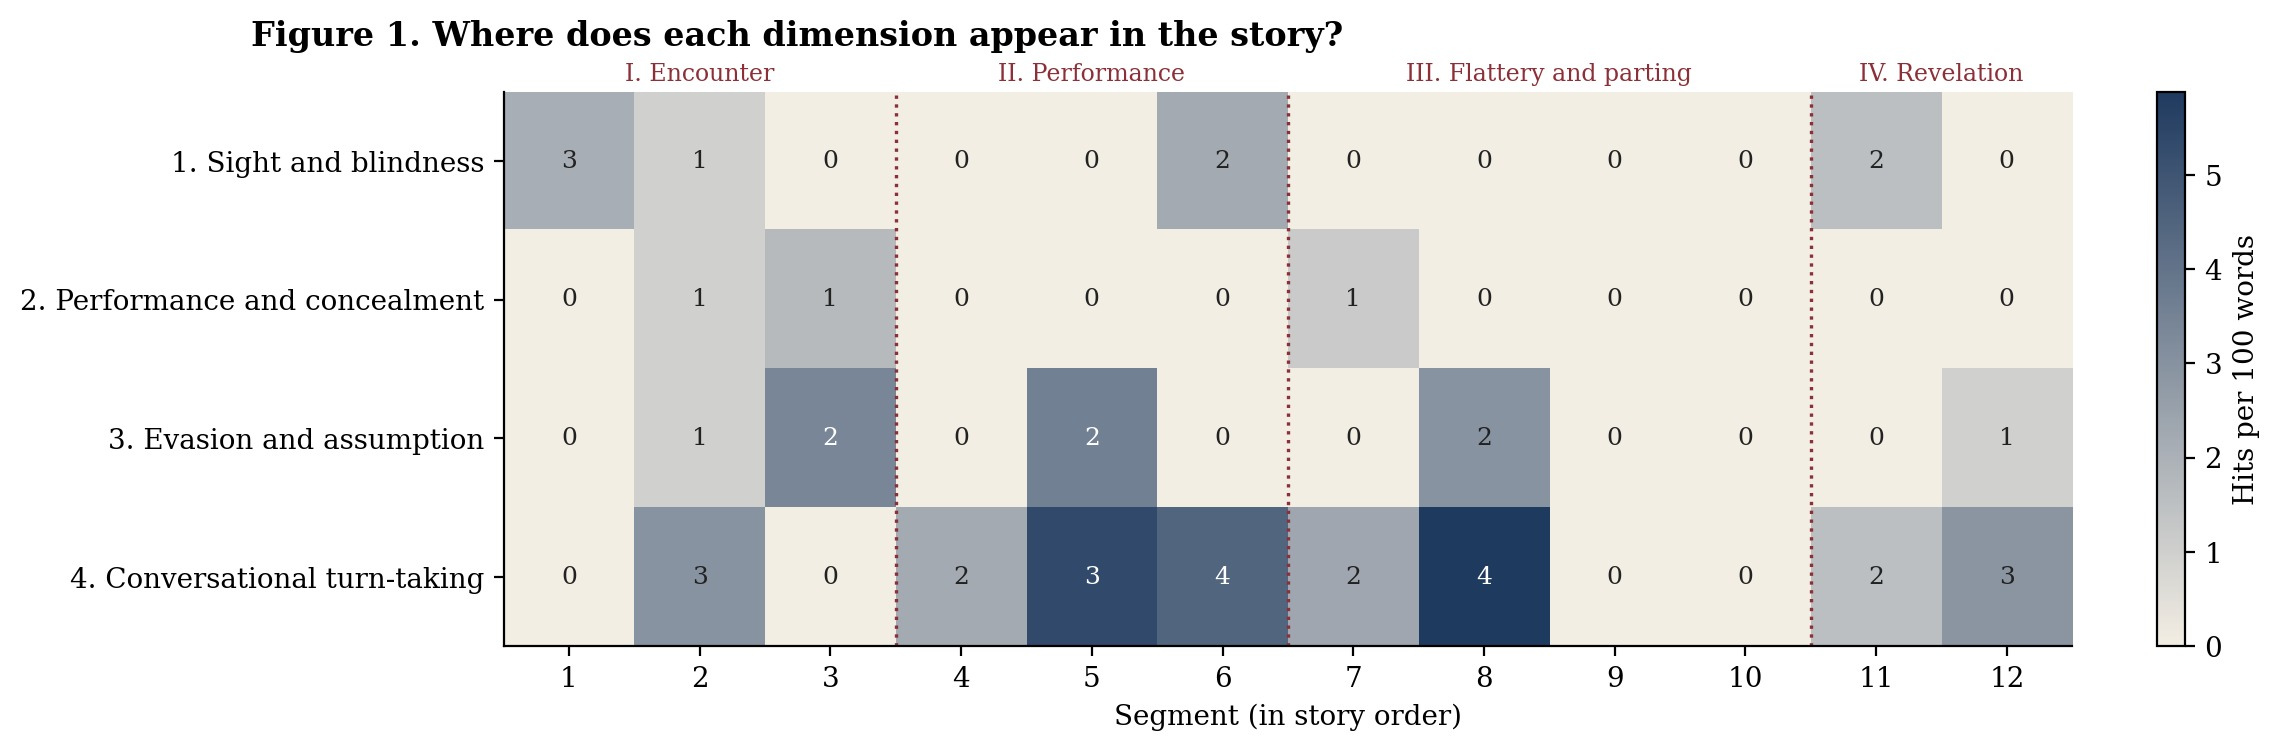

In [25]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image

plt.rcParams.update({"font.family": "serif", "font.serif": ["DejaVu Serif"], "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

def stage_marks(ax, y_text):
    for st, a, b in stage_span:
        if a != 1:
            ax.axvline(a - 0.5, color=OXBLOOD, lw=1.2, ls=":")
        ax.text((a + b) / 2, y_text, st, ha="center", va="bottom", color=OXBLOOD, fontsize=8.5,
                transform=ax.get_xaxis_transform())

def save(fig, name, title):
    fig.suptitle(title, x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.savefig(f"figures/{name}.jpg", dpi=200, bbox_inches="tight", pil_kwargs={"quality": 92})
    plt.close(fig)

# Figure 1
f, ax = plt.subplots(figsize=(11, 3.6))
cmap = matplotlib.colors.LinearSegmentedColormap.from_list("ink", ["#f3eee4", INK])
im = ax.imshow(np.array(dens), aspect="auto", cmap=cmap, extent=[0.5, n + 0.5, len(DIMS) - 0.5, -0.5])
for a in range(len(DIMS)):
    for b, i in enumerate(ids):
        v = np.array(dens).max() or 1
        ax.text(i, a, raw[a][b], ha="center", va="center", fontsize=9,
                color="white" if dens[a][b] > 0.55 * v else "#222")
ax.set_yticks(range(len(DIMS)), [dim_label[d] for d in DIMS]); ax.set_xticks(ids)
ax.set_xlabel("Segment (in story order)"); stage_marks(ax, 1.01)
f.colorbar(im, ax=ax, label="Hits per 100 words", fraction=0.03)
save(f, FIG_FILES[0], "Figure 1. Where does each dimension appear in the story?")

# Figure 2
f, ax = plt.subplots(figsize=(11, 5.4))
ylab = [sub_label[k] for k in SUBS]
for di, d in enumerate(DIMS):
    for (dd, s) in SUBS:
        if dd != d:
            continue
        for i in ids:
            v = sum(by_seg_sub[(i, (dd, s))].values())
            if v:
                ax.scatter(i, len(SUBS) - 1 - ylab.index(sub_label[(dd, s)]), s=40 + 900 * v / mx,
                           color=PALETTE[di], alpha=0.8, edgecolor="white")
ax.set_yticks(range(len(SUBS)), ylab[::-1]); ax.set_xticks(ids); ax.set_xlim(0.5, n + 0.5)
ax.set_ylim(-0.7, len(SUBS) - 0.3); ax.set_xlabel("Segment (in story order)"); stage_marks(ax, 1.01)
ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=PALETTE[i], label=dim_label[d]) for i, d in enumerate(DIMS)],
          loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False, fontsize=8.5)
save(f, FIG_FILES[1], "Figure 2. Which sub-types are strongest, and where?")

# Figure 3
f, ax = plt.subplots(figsize=(10, 4.4))
w = 0.8 / len(DIMS); x = np.arange(len(stage_names))
for di, d in enumerate(DIMS):
    ax.bar(x + (di - 1.5) * w, [stage_dens.loc[d, st] for st in stage_names], w, color=PALETTE[di], label=dim_label[d])
ax.set_xticks(x, stage_names); ax.set_ylabel("Hits per 100 words")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4, frameon=False, fontsize=8.5)
save(f, FIG_FILES[2], "Figure 3. How do the stages differ?")

# Figure 4
f, ax = plt.subplots(figsize=(11, 4.4))
for di, d in enumerate(DIMS):
    ax.plot(ids, [seg_dens.loc[d, i] for i in ids], marker="o", lw=2.2, color=PALETTE[di], label=dim_label[d])
ax.set_xticks(ids); ax.set_xlim(0.5, n + 0.5); ax.set_xlabel("Segment (in story order)")
ax.set_ylabel("Hits per 100 words"); stage_marks(ax, 1.01)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=4, frameon=False, fontsize=8.5)
save(f, FIG_FILES[3], "Figure 4. How does each dimension change across the story?")

# Figure 5
f, ax = plt.subplots(figsize=(9, 5))
if common:
    ax.barh([show(k) for k, _ in common][::-1], [v for _, v in common][::-1],
            color=[PALETTE[DIMS.index(item_dim[k])] for k, _ in common][::-1])
ax.set_xlabel("Number of occurrences"); ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
ax.legend(handles=[matplotlib.patches.Patch(color=PALETTE[i], label=dim_label[d]) for i, d in enumerate(DIMS)],
          loc="lower right", frameon=False, fontsize=8)
save(f, FIG_FILES[4], "Figure 5. Which phrases carry the most weight?")

# Figure 6
f, ax = plt.subplots(figsize=(10, 4.4))
x = np.arange(len(VOICES))
for di, d in enumerate(DIMS):
    ax.bar(x + (di - 1.5) * w, [voice_dens.loc[d, v] for v in VOICES], w, color=PALETTE[di], label=dim_label[d])
ax.set_xticks(x, [VOICE_LABELS[v].replace(": ", ":\n") for v in VOICES]); ax.set_ylabel("Hits per 100 words of the voice")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=4, frameon=False, fontsize=8.5)
save(f, FIG_FILES[5], "Figure 6. Whose words carry each dimension?")

print("Saved JPG figures:", ", ".join(f"figures/{x}.jpg" for x in FIG_FILES))
display(Image("figures/fig1_heatmap.jpg", width=900))

## Step 7. Interpretation

### 7.1 What each figure shows

**What I am doing.** For each figure I write how to read it and what it shows. The "what it shows" sentences are **built from the numbers of this run**, so they always agree with the figures, even if the model or the lexicon changes.

In [26]:
f1 = lambda x: f"{x:.1f}"
f2 = lambda x: f"{x:.2f}"
DL = {d: DIMENSIONS[d]["label"] for d in DIMS}
dl = {d: DL[d][0].lower() + DL[d][1:] for d in DIMS}
dl["turn_taking"] = "turn-taking"
stage_short = {st: "Stage " + st.split(".")[0] for st in stage_names}
cap = lambda s: s[:1].upper() + s[1:]

def peak_segment(d):
    row = seg_dens.loc[d]
    i = int(row.idxmax())
    return i, row[i]

def interp_fig1():
    parts = []
    for d in DIMS:
        if seg_counts.loc[d].sum() == 0:
            parts.append(f"{dl[d]} has no hits")
            continue
        i, v = peak_segment(d)
        empty = [str(j) for j in ids if seg_counts.loc[d, j] == 0]
        parts.append(f"{dl[d]} is densest in segment {i} ({seg_of[i]['note']}: {f1(v)} per 100 words)"
                     + (f" and absent from segment{'s' if len(empty) > 1 else ''} {', '.join(empty)}" if empty else ""))
    return cap("; ".join(parts) + ".")

def interp_fig2():
    tot = sub_counts.sum(axis=1).sort_values(ascending=False)
    lead = ", ".join(f"{pretty(s).lower()} ({int(v)} hits)" for (d, s), v in tot.head(3).items() if v)
    zero = [pretty(s).lower() for (d, s), v in tot.items() if v == 0]
    out = f"The largest sub-types are {lead}." if lead else "No sub-type has any hits."
    if zero:
        out += f" No hits were found for: {', '.join(zero)}."
    return out

def interp_fig3():
    parts = []
    for d in DIMS:
        if stage_counts.loc[d].sum() == 0:
            continue
        st = stage_dens.loc[d].idxmax()
        parts.append(f"{dl[d]} peaks in {stage_short[st]} ({f2(stage_dens.loc[d, st])} per 100 words; "
                     f"range {f2(stage_dens.loc[d].min())} to {f2(stage_dens.loc[d].max())})")
    return cap("; ".join(parts) + ".") if parts else "No dimension has any hits."

def trend(d):
    t = TESTS[d]
    if t["rho"] is None:
        return f"{dl[d]} cannot be tested for a trend"
    if t["rho_p"] < 0.05:
        return f"{dl[d]} {'rises' if t['rho'] > 0 else 'falls'} steadily (Spearman rho = {t['rho']:+.2f}, p = {t['rho_p']:.3f})"
    return f"{dl[d]} shows no steady trend (rho = {t['rho']:+.2f}) and moves in bursts"

def interp_fig4():
    return cap("; ".join(trend(d) for d in DIMS) + ".")

def interp_fig5():
    c = Counter(r["item"] for r in rows).most_common(5)
    if not c:
        return "No phrases were matched."
    return ("The most frequent items are " + ", ".join(f"\"{show(k)}\" ({v})" for k, v in c)
            + f". Together, the 15 most frequent items account for {sum(v for _, v in common)} of the {len(rows)} hits.")

def interp_fig6():
    parts = []
    for d in DIMS:
        if voice_counts.loc[d].sum() == 0:
            continue
        v = voice_dens.loc[d].idxmax()
        parts.append(f"{dl[d]} is densest in {VOICE_PHRASE[v]} "
                     f"({f2(voice_dens.loc[d, v])} per 100 words)")
    g = voice_counts["girl"].sum()
    return (cap("; ".join(parts) + ".")
            + f" The girl's {voice_words['girl']} words contain {int(g)} hits in all; the man's {voice_words['man']} words contain {int(voice_counts['man'].sum())}.")

INTERPRETATION = {1: interp_fig1(), 2: interp_fig2(), 3: interp_fig3(), 4: interp_fig4(), 5: interp_fig5(), 6: interp_fig6()}
HOW = {
    1: "Each row is one dimension and each column is one segment of the story, in order. The number in each square is the number of hits; the shade shows hits per 100 words, so short and long segments can be compared. Dotted red lines mark where a new stage begins.",
    2: "Each row is one sub-type (the number in brackets is its dimension). Each bubble is a segment. A bigger bubble means more phrases of that sub-type in that segment.",
    3: "The story is grouped into four stages. Each bar shows hits per 100 words, so a longer stage does not look stronger only because it is longer.",
    4: "Each line is one dimension followed across the segments in story order, in hits per 100 words. A rising line means that the dimension grows denser as the story moves on.",
    5: "The fifteen most frequent phrases in the extraction, coloured by dimension.",
    6: "Each group of bars is one voice: the narrator's narration and thoughts, the narrator speaking aloud, the girl, and the man who boards at Saharanpur. Each bar shows hits per 100 words of that voice, so the girl's short speeches can be compared with the narrator's long narration.",
}
TITLES = {1: "Figure 1. Where does each dimension appear in the story?",
          2: "Figure 2. Which sub-types are strongest, and where?",
          3: "Figure 3. How do the stages differ?",
          4: "Figure 4. How does each dimension change across the story?",
          5: "Figure 5. Which phrases carry the most weight?",
          6: "Figure 6. Whose words carry each dimension?"}
for k in TITLES:
    display(Markdown(f"**{TITLES[k]}** {HOW[k]}\n\n*What it shows:* {INTERPRETATION[k]}"))

**Figure 1. Where does each dimension appear in the story?** Each row is one dimension and each column is one segment of the story, in order. The number in each square is the number of hits; the shade shows hits per 100 words, so short and long segments can be compared. Dotted red lines mark where a new stage begins.

*What it shows:* Sight and blindness is densest in segment 6 (At the window: the pretence of looking: 2.2 per 100 words) and absent from segments 3, 4, 5, 7, 8, 9, 10, 12; performance and concealment is densest in segment 3 (The resolve to hide, and the aunt at Saharanpur: 1.7 per 100 words) and absent from segments 1, 4, 5, 6, 8, 9, 10, 11, 12; evasion and assumption is densest in segment 5 ("What is it like outside?": 3.6 per 100 words) and absent from segments 1, 4, 6, 7, 9, 10, 11; turn-taking is densest in segment 8 (Gallant and serious, and the journey's end: 5.9 per 100 words) and absent from segments 1, 3, 9, 10.

**Figure 2. Which sub-types are strongest, and where?** Each row is one sub-type (the number in brackets is its dimension). Each bubble is a segment. A bigger bubble means more phrases of that sub-type in that segment.

*What it shows:* The largest sub-types are turn markers (13 hits), questions (6 hits), assumption (5 hits). No hits were found for: revelation.

**Figure 3. How do the stages differ?** The story is grouped into four stages. Each bar shows hits per 100 words, so a longer stage does not look stronger only because it is longer.

*What it shows:* Sight and blindness peaks in Stage I (1.31 per 100 words; range 0.00 to 1.31); performance and concealment peaks in Stage I (0.65 per 100 words; range 0.00 to 0.65); evasion and assumption peaks in Stage I (0.98 per 100 words; range 0.43 to 0.98); turn-taking peaks in Stage II (3.80 per 100 words; range 0.98 to 3.80).

**Figure 4. How does each dimension change across the story?** Each line is one dimension followed across the segments in story order, in hits per 100 words. A rising line means that the dimension grows denser as the story moves on.

*What it shows:* Sight and blindness shows no steady trend (rho = -0.29) and moves in bursts; performance and concealment shows no steady trend (rho = -0.40) and moves in bursts; evasion and assumption shows no steady trend (rho = -0.22) and moves in bursts; turn-taking shows no steady trend (rho = +0.02) and moves in bursts.

**Figure 5. Which phrases carry the most weight?** The fifteen most frequent phrases in the extraction, coloured by dimension.

*What it shows:* The most frequent items are "I said" (3), "I asked" (2), "my eyes sensitive only to light and darkness" (1), "I was totally blind at the time" (1), "the sound of her slippers" (1). Together, the 15 most frequent items account for 18 of the 42 hits.

**Figure 6. Whose words carry each dimension?** Each group of bars is one voice: the narrator's narration and thoughts, the narrator speaking aloud, the girl, and the man who boards at Saharanpur. Each bar shows hits per 100 words of that voice, so the girl's short speeches can be compared with the narrator's long narration.

*What it shows:* Sight and blindness is densest in the narrator's narration and thoughts (0.96 per 100 words); performance and concealment is densest in the narrator's speech (0.56 per 100 words); evasion and assumption is densest in the narrator's speech (1.67 per 100 words); turn-taking is densest in the narrator's speech (6.11 per 100 words). The girl's 135 words contain 6 hits in all; the man's 55 words contain 2.

### 7.2 Testing the four claims

**What I am doing.** I test the four claims of Step 2 against the counts. Each test is written out as a rule, so the verdict follows from the numbers and not from my hopes:

- **C1** compares the share of *imagined sight* hits that fall in the middle stages (II and III) with the share of the story's words in those stages.
- **C2** checks two things: whether at least three-quarters of the *pretence* and *concealment* hits fall in the conversation (Stages I–III), and whether at least half of the *revelation* hits fall in Stage IV.
- **C3** compares the rate of *evasion and assumption* markers in the girl's speech with the rate in the narrator's words.
- **C4** compares the density of *turn-taking* in Stages I–III with its density in Stage IV.

In [27]:
MIDDLE, CONVERSATION, END = stage_names[1:3], stage_names[:3], stage_names[3:]
words_in = lambda sts: sum(stage_words[s] for s in sts)

def hits(dim=None, subs=None, stages=None, voices=None):
    q = df
    if dim:
        q = q[q["dimension"] == dim]
    if subs:
        q = q[q["sub"].isin(subs)]
    if stages:
        q = q[q["stage"].isin(stages)]
    if voices:
        q = q[q["voice"].isin(voices)]
    return len(q)

def test_c1():
    h, hm = hits("sight_and_blindness", ["imagined_sight"]), hits("sight_and_blindness", ["imagined_sight"], MIDDLE)
    ws = words_in(MIDDLE) / total_words
    if h < 3:
        return "Inconclusive", f"only {h} hit(s) of imagined sight were found, too few to judge"
    sh = hm / h
    ev = (f"{hm} of the {h} imagined-sight hits ({sh:.0%}) fall in Stages II and III, "
          f"which hold {ws:.0%} of the story's words")
    return ("Supported" if sh >= ws + 0.15 else "Partly supported" if sh > ws else "Not supported"), ev

def test_c2():
    pc = hits("performance_and_concealment", ["pretence", "concealment"])
    pc_conv = hits("performance_and_concealment", ["pretence", "concealment"], CONVERSATION)
    rv = hits("performance_and_concealment", ["revelation"])
    rv_end = hits("performance_and_concealment", ["revelation"], END)
    a_ok = pc > 0 and pc_conv / pc >= 0.75
    b_ok = rv > 0 and rv_end / rv >= 0.5
    ev = (f"{pc_conv} of {pc} pretence and concealment hits fall in Stages I–III" if pc else "no pretence or concealment hits were found")
    ev += "; " + (f"{rv_end} of {rv} revelation hits fall in Stage IV" if rv else "no revelation hits were found")
    return ("Supported" if a_ok and b_ok else "Partly supported" if a_ok or b_ok else "Not supported"), ev

def test_c3():
    g = hits("evasion_and_assumption", voices=["girl"])
    nn = hits("evasion_and_assumption", voices=["narration", "narrator_aloud"])
    wg, wn = voice_words["girl"], voice_words["narration"] + voice_words["narrator_aloud"]
    rg, rn = 100 * g / wg, 100 * nn / wn
    ev = (f"the girl's speech has {g} markers ({f2(rg)} per 100 words); "
          f"the narrator's narration and speech have {nn} ({f2(rn)} per 100 words)")
    if g == 0:
        return "Not supported", ev
    return ("Supported" if rn == 0 or rg >= 0.5 * rn else "Partly supported"), ev

def test_c4():
    c, e = hits("turn_taking", stages=CONVERSATION), hits("turn_taking", stages=END)
    dc, de = 100 * c / words_in(CONVERSATION), 100 * e / words_in(END)
    ev = f"turn-taking has {f2(dc)} hits per 100 words in Stages I–III and {f2(de)} in Stage IV"
    if c == 0:
        return "Inconclusive", ev
    return ("Supported" if dc > 1.25 * de else "Partly supported" if dc > de else "Not supported"), ev

CLAIM_RESULTS = {"C1": test_c1(), "C2": test_c2(), "C3": test_c3(), "C4": test_c4()}
claim_table = pd.DataFrame([{"claim": k, "statement": CLAIMS[k], "verdict": v, "evidence": e}
                            for k, (v, e) in CLAIM_RESULTS.items()])
claim_table.to_csv("extraction/claim_tests.csv", index=False)
claim_table

,claim,statement,verdict,evidence
0,C1,"Imagined sight (memory, guesswork, the mind's ...",Inconclusive,"only 1 hit(s) of imagined sight were found, to..."
1,C2,The language of pretence and concealment runs ...,Partly supported,3 of 3 pretence and concealment hits fall in S...
2,C3,Markers of evasion and assumption appear in th...,Not supported,the girl's speech has 0 markers (0.00 per 100 ...
3,C4,Turn-taking is densest while the narrator and ...,Not supported,turn-taking has 2.08 hits per 100 words in Sta...


### 7.3 The interpretation essay

**What I am doing.** I read the patterns through literary and linguistic theory and check them against a close reading of the whole story. The essay answers the two research questions, tests the claims, returns to my initial impression and states the limits of the method.

The essay is written so that **every number in it comes from this run**: the numbers and the verdicts are filled in from the tables above, while the close reading of the passages stays the same. If you change the model, the lexicon or the stages, run this cell again and read the essay through, because the meaning of a sentence can change when its numbers do.

The cell saves `docs/interpretation.md` and displays it.

In [28]:
# ---------- helpers that turn the results into prose ----------
def pfmt(p):
    return "p < .001" if p < 0.001 else f"p = {p:.3f}".replace("0.", ".")

def items_of(dim=None, sub=None, stages=None, voices=None, k=4):
    q = df
    if dim: q = q[q["dimension"] == dim]
    if sub: q = q[q["sub"] == sub]
    if stages: q = q[q["stage"].isin(stages)]
    if voices: q = q[q["voice"].isin(voices)]
    c = Counter(q["item"]).most_common(k)
    return ", ".join(f"“{show(x)}”" + (f" ({v})" if v > 1 else "") for x, v in c) or "none"

def stage_series(d, sub=None):
    vals = sub_dens.loc[(d, sub)] if sub else stage_dens.loc[d]
    return ", ".join(f"{f2(vals[st])} in {stage_short[st]}" for st in stage_names)

def where_peak(d, sub=None):
    vals = sub_dens.loc[(d, sub)] if sub else stage_dens.loc[d]
    return stage_short[vals.idxmax()] if vals.max() > 0 else "no stage"

def sub_total(d, s):
    return int(sub_counts.loc[(d, s)].sum())

def chi_text(d):
    t = TESTS[d]
    if t["chi2"] is None:
        return f"{dl[d]} has too few hits for the test"
    verdict = "rejects an even spread" if t["chi_p"] < 0.05 else "does not reject an even spread"
    return f"{dl[d]} {verdict} (chi-square {t['chi2']:.1f}, {pfmt(t['chi_p'])})"

dim_totals = df.groupby("dimension").size().reindex(DIMS, fill_value=0).sort_values(ascending=False)
N, W = len(df), total_words
gw, nw = voice_words["girl"], voice_words["narration"] + voice_words["narrator_aloud"]
ea_g, ea_n = hits("evasion_and_assumption", voices=["girl"]), hits("evasion_and_assumption", voices=["narration", "narrator_aloud"])
q = QUESTIONS_BY_VOICE

E = []
E.append("# Interpretation: sight, blindness and mutual concealment in “The Eyes Have It”")

E.append("## 7.1 Research paradigm, and what the figures can and cannot show")
E.append("This study follows the synthetic reading method of Ghosh, Shanmugapriya T and Mandal (2026), in which interpretation comes before computation. My initial impression, written after reading 21 of the 99 sentences, was not a hypothesis for software to prove. It was the situated reading from which the four dimensions, the prompt and the four claims were built. The approach is reader-oriented: following Iser (1978), I take the meaning of a literary text to be realised in the act of reading. This story makes the point itself, because its last four sentences change the meaning of everything that a first reader has read before them.")
E.append("The computational steps follow the spirit of algorithmic criticism (Ramsay, 2011). The model and the counts do not interpret the story. They rearrange its language so that patterns a single reading may miss become available for argument. The counts are descriptive: they show where the four dimensions are expressed in the vocabulary of the story, not what the story means, and no number below should be read as a finding without the close reading that goes with it.")
E.append(f"The extraction by {MODEL_NAME} produced {n_ver} verified phrases. They occur {N} times in the {W:,} words of the story ({f1(100 * N / W)} occurrences per 100 words). Each occurrence is assigned to exactly one sub-type, so nothing is counted twice. By dimension the totals are: "
         + ", ".join(f"{dl[d]} {int(v)}" for d, v in dim_totals.items()) + ".")

E.append("## 7.2 Summary of the evidence")
for d in DIMS:
    if stage_counts.loc[d].sum() == 0:
        E.append(f"**{DL[d]}.** The extraction found no hits for this dimension, so the argument below relies on close reading alone.")
        continue
    E.append(f"**{DL[d]}.** Per 100 words, this dimension has {stage_series(d)}; it peaks in {where_peak(d)}. "
             f"Its most frequent items are {items_of(d, k=5)}.")
E.append("A chi-square test of each dimension's spread across the four stages, against the length of the stages (3 degrees of freedom), shows the following: "
         + "; ".join(chi_text(d) for d in DIMS) + ". A Spearman correlation between segment order and density gives the following: "
         + "; ".join(trend(d) for d in DIMS)
         + ". Because hits within a passage are not independent, I treat these tests as a rough guide to which patterns are unlikely to be accidents, not as formal proof.")

E.append("## 7.3 Research question 1: the metaphor of sight and blindness")
E.append("The story tells the reader that the narrator is blind in its second paragraph (“my eyes sensitive only to light and darkness”), but he hides it from the girl. From that moment the reader holds information that the girl seems not to have, and every later word of seeing is read twice: as what the narrator says, and as what he cannot do. The title already makes sight a matter of judgement as well as perception. “The Eyes Have It” echoes the parliamentary formula “the ayes have it”, which announces the result of a vote. At the end, it is the man with working eyes who announces what the narrator, and the reader, did not know.")
sb_total = int(stage_counts.loc["sight_and_blindness"].sum())
if sb_total:
    E.append(f"The dimension of sight and blindness has {sb_total} hits. Literal sight accounts for {sub_total('sight_and_blindness', 'literal_sight')} of them, imagined sight for {sub_total('sight_and_blindness', 'imagined_sight')}, and the substitute senses for {sub_total('sight_and_blindness', 'substitute_senses')}. "
             f"Literal sight peaks in {where_peak('sight_and_blindness', 'literal_sight')} ({stage_series('sight_and_blindness', 'literal_sight')} per 100 words), and its most frequent items are {items_of('sight_and_blindness', 'literal_sight')}. "
             f"Imagined sight peaks in {where_peak('sight_and_blindness', 'imagined_sight')}, with items such as {items_of('sight_and_blindness', 'imagined_sight', k=3)}; the substitute senses peak in {where_peak('sight_and_blindness', 'substitute_senses')}, with items such as {items_of('sight_and_blindness', 'substitute_senses', k=3)}.")
E.append("Early in the story, the narrator states its theory of sight in a general aside: “it often happens that people with good eyesight fail to see what is right in front of them”, whereas “people who cannot see (or see very little) have to take in only the essentials, whatever registers tellingly on their remaining senses”. The rest of the story tests this claim. Sight is redefined as attention rather than as the work of the eyes, which is close to Merleau-Ponty's (1945/2012) account of perception as the activity of a whole body rather than of a single organ. The narrator knows the girl through her slippers “slapped against her heels”, her voice, which “had the sparkle of a mountain stream”, and “the perfume from her hair”. The ending confirms the aside in an unexpected way: the sighted man noticed the girl's eyes but cannot say whether her hair was long or short.")
E.append("The narrator's performance depends on the conventions of sighted speech. Martin Jay (1993) describes how deeply Western thought ties knowing to seeing, and the narrator exploits exactly this habit. He describes Mussoorie by “calling on my memories”, so that remembered sight (“The hills are covered with wild dahlias”) passes for present sight. At the window he “felt for the window ledge” and made “a pretence of studying the landscape”, while “in my mind's eye I could see telegraph posts flashing by”: the picture is built from “the panting of the engine, the rumble of the wheels”. His remark that “the trees seem to be moving while we seem to be standing still” is a commonplace of sighted travel, offered as if it were an observation, and his confident “No” to “Do you see any animals?” rests on knowledge, not on sight. Georgina Kleege (1999), writing as a blind author, observes that blind people learn the visual vocabulary of the sighted and are expected to use it. The narrator's fluency in that vocabulary is what lets him pass. In Goffman's (1963) terms, he is a “discreditable” person, whose stigma is not yet known, managing information about himself: “Once again I had a game to play.”")
E.append("Near the end, the metaphor turns into a paradox: the narrator sits “staring into the daylight that was darkness for me” and thinks that “it could be a fascinating game guessing what went on out there”. For him, seeing has become guessing. The last sentences then show that the girl was guessing too. Mitchell and Snyder (2000) call this use of disability a “narrative prosthesis”: the girl's blindness is withheld and then used to give the story its ending. The one who names it is the man, the only sighted character, whom Garland-Thomson (1997) would call the normate, the figure against whom bodies are judged. His last words, “She was completely blind. Didn't you notice?”, turn the question of sight back on the narrator and on the reader, who also assumed that the girl could see.")
E.append("My answer to the first question, then, is that sight and blindness in this story work as a metaphor for knowing other people. To see is to notice, infer and judge; to be blind is to lack information. The story distributes that blindness to everyone: to the narrator, who cannot see; to the girl, who cannot see and, he assumes, cannot see that he cannot; to the sighted man, who did not notice her hair; and to the reader, who did not notice that the girl was blind.")

E.append("## 7.4 Research question 2: evasion, assumption and turn-taking")
ea_total, tt_total = int(stage_counts.loc["evasion_and_assumption"].sum()), int(stage_counts.loc["turn_taking"].sum())
E.append(f"The dimension of evasion and assumption has {ea_total} hits ({stage_series('evasion_and_assumption')} per 100 words), and turn-taking has {tt_total} ({stage_series('turn_taking')}). "
         f"By voice, the girl's {gw} words contain {ea_g} markers of evasion and assumption ({f2(100 * ea_g / gw)} per 100 words), and the narrator's {nw} words of narration and speech contain {ea_n} ({f2(100 * ea_n / nw)}). "
         f"Most frequent in the girl's speech are {items_of('evasion_and_assumption', voices=['girl'])}; in the narrator's words, {items_of('evasion_and_assumption', voices=['narration', 'narrator_aloud'])}.")
E.append(f"Read as conversation analysis (Sacks, Schegloff and Jefferson, 1974), the exchange is an orderly sequence of questions and answers. The narrator asks {q['narrator_aloud']} questions aloud and {q['narration']} silently, to himself; the girl asks {q['girl']}; the man asks {q['man']}. "
         "The girl's questions are the most revealing turns in the story. “Why don't you look out of the window?” and “Do you see any animals?” invite the narrator to perform sight, and he accepts the invitation. Read again after the ending, they may be the questions of a blind girl who is also performing, or testing. The narrator's “What is it like outside?” is the only question that could expose him, and he calls it “a mistake”. The answer he fears never comes: “She seemed to find nothing strange in the question.” The question-and-answer pairs are completed, but neither speaker uses them to find out what the other can see.")
E.append("Evasion works through what Grice (1975) calls the cooperative principle: speakers are expected to say as much as the exchange requires, and both travellers say less. The girl answers the observation about the moving trees with “That always happens”, a general reply that confirms what she cannot check. She answers the compliment on her face by reporting what other people say: “I'm tired of people telling me I have a pretty face.” She closes the subject of the journey with “Thank goodness it's a short journey.” The narrator deflects with humour (“Aunts are usually formidable creatures”) and chooses a compliment because it cannot be checked: “it was a safe remark.” Compliments and polite formulas also do what Goffman (1967) calls face-work, and Brown and Levinson (1987) politeness: they protect each speaker's self-image and keep the talk going without anyone having to confirm a fact. “You are a very gallant young man,” she says; “But why are you so serious?” is the one moment when she seems to read him.")
E.append("Assumption is marked by the grammar of guessing: “probably her parents”, “I suppose”, “I must have been sitting in a dark corner”, “She seemed to find nothing strange”, “That voice must have belonged to the girl's aunt”, “Perhaps it was hanging loose over her shoulders”. The narrator infers the world from sound, and the reader infers with him. His silent question, “Had she noticed already that I could not see?”, asks what she knows about him; he never asks what she can see. Silence marks the turns where each might have found the other out: “She was silent”, and “for a while we sat in silence”. The conversation closes with “Goodbye”, and the man “broke into my reverie”. The story ends on a question that nobody in it answers, “Didn't you notice?”, so that the final turn passes to the reader.")
E.append("The information asymmetry is therefore not a simple contrast between a blind man and a sighted girl. It has three sides: the narrator knows his own secret and not hers; the girl, as the ending suggests, may know her own and not his; and the man knows hers but not the narrator's. The reader is placed with the narrator until the last line. The deception is mutual because both travellers use the same means: polite questions, general answers, compliments that cannot be checked, and silence. "
         + (f"The counts agree: the girl's speech has {f2(100 * ea_g / gw)} markers of evasion and assumption per 100 words, against {f2(100 * ea_n / nw)} in the narrator's words (see claim C3)."
            if CLAIM_RESULTS["C3"][0] == "Supported" else
            f"The counts qualify this: the girl's speech has {f2(100 * ea_g / gw)} markers of evasion and assumption per 100 words, against {f2(100 * ea_n / nw)} in the narrator's words (see claim C3), so in the language the concealment is carried mostly by the narrator, and the girl's part in it is shown by the ending rather than by her vocabulary."))

E.append("## 7.5 Testing the claims")
E.append("\n".join(f"- **{k} ({verdict}).** {CLAIMS[k]} Evidence: {ev}." for k, (verdict, ev) in CLAIM_RESULTS.items()))

E.append("## 7.6 Return to my initial impression")
E.append("My partial reading suggested that, in isolated blocks, the story's language of seeing reads as eyewitness description, standard metaphor and ordinary chatter. The full reading confirms this observation and changes its meaning: the effect I noticed in fragments is the effect that the story works on any first reader. The context that the blocks removed is exactly the context that turns description into performance. The dahlias are introduced by “calling on my memories”; the mind's eye follows “the panting of the engine, the rumble of the wheels”; and the chatter is framed by the narrator's commentary (“it was a safe remark”, “Few girls can resist flattery”). The ending adds a layer that my partial reading could not reach. The polite talk I read as “mundane pragmatics” is also where the girl may have been hiding her own blindness, so that the tension of mutual concealment, which I could not hear in the fragments, is there after all, in a form that only the last sentences reveal.")

E.append("## 7.7 The reader's position and the role of the model")
E.append("I read the story as a sighted reader, trained in comparative literature and now in the digital humanities. My sightedness matters most: the ending works on readers like me, who assume that the people in a story can see unless they are told otherwise. I have tried to read blindness through the work of disability scholars, including a blind writer, rather than through sighted assumptions, but my reading remains a sighted one. The model complemented my reading rather than replacing it: it listed the hedges, the reporting verbs and the questions, which a reader following the plot passes over, and so made the grammar of guessing visible. The dimensions themselves came from my partial reading. Another reader, with a different history, might have begun with gender, the comedy of manners or travel writing, and would have built different dimensions and a different table of results.")

E.append("## 7.8 Limitations")
E.append(f"- The method depends on a word list. A word such as “see”, “face” or “notice” can have several senses, and counting treats them alike.\n"
         f"- The extraction was done by a language model from my prompt. Of the {n_raw} phrases it returned, {n_ver} were verified word for word and kept and {len(removed)} were removed. The choice of what to extract is a judgement that another model, or another reader, might make differently.\n"
         "- The segments, the stages and the voice of each sentence are my own annotations. A different division would change the stage figures.\n"
         "- The story is a single short text of about 1,100 words, and short segments can produce high densities from a few hits.\n"
         "- Counts show vocabulary, not tone. Irony, and the meaning of silence, are only partly captured by phrases.")

E.append("## 7.9 Conclusion")
E.append("“The Eyes Have It” builds its effect from ordinary language. The words of seeing, the polite questions, the compliments and the guesses all look innocent in isolation, which is what my partial reading showed. In the whole story they become a performance of sight by a blind narrator and, as the last sentences suggest, perhaps a performance answered by another. The metaphor of sight and blindness is a metaphor for knowing other people, and the grammar of evasion and assumption shows how two strangers manage not to know each other. The final question, “Didn't you notice?”, is asked of the narrator, but it is also asked of every reader who assumed that the girl could see.")

E.append("## Works cited")
E.append("- Bond, R. (1988). The eyes have it. In *The Night Train at Deoli and Other Stories*. Penguin Books.\n"
         "- Brown, P., & Levinson, S. C. (1987). *Politeness: Some Universals in Language Usage*. Cambridge University Press.\n"
         "- Garland-Thomson, R. (1997). *Extraordinary Bodies: Figuring Physical Disability in American Culture and Literature*. Columbia University Press.\n"
         "- Ghosh, S., Shanmugapriya T, & Mandal, S. (2026). Synthetic reading: Towards a hermeneutic-computational method for literary interpretation through Tagore's “A Wife's Letter”. *International Journal of Humanities and Arts Computing*, 20(2), 216–237. https://doi.org/10.3366/ijhac.2026.0378\n"
         "- Goffman, E. (1963). *Stigma: Notes on the Management of Spoiled Identity*. Prentice-Hall.\n"
         "- Goffman, E. (1967). *Interaction Ritual: Essays on Face-to-Face Behavior*. Anchor Books.\n"
         "- Grice, H. P. (1975). Logic and conversation. In P. Cole & J. L. Morgan (Eds.), *Syntax and Semantics, Vol. 3: Speech Acts* (pp. 41–58). Academic Press.\n"
         "- Iser, W. (1978). *The Act of Reading: A Theory of Aesthetic Response*. Johns Hopkins University Press.\n"
         "- Jay, M. (1993). *Downcast Eyes: The Denigration of Vision in Twentieth-Century French Thought*. University of California Press.\n"
         "- Kleege, G. (1999). *Sight Unseen*. Yale University Press.\n"
         "- Merleau-Ponty, M. (2012). *Phenomenology of Perception* (D. A. Landes, Trans.). Routledge. (Original work published 1945)\n"
         "- Mitchell, D. T., & Snyder, S. L. (2000). *Narrative Prosthesis: Disability and the Dependencies of Discourse*. University of Michigan Press.\n"
         "- Ramsay, S. (2011). *Reading Machines: Toward an Algorithmic Criticism*. University of Illinois Press.\n"
         "- Sacks, H., Schegloff, E. A., & Jefferson, G. (1974). A simplest systematics for the organization of turn-taking for conversation. *Language*, 50(4), 696–735.")

ESSAY = "\n\n".join(E)
open("docs/interpretation.md", "w", encoding="utf-8").write(ESSAY)
display(Markdown(ESSAY))

# Interpretation: sight, blindness and mutual concealment in “The Eyes Have It”

## 7.1 Research paradigm, and what the figures can and cannot show

This study follows the synthetic reading method of Ghosh, Shanmugapriya T and Mandal (2026), in which interpretation comes before computation. My initial impression, written after reading 21 of the 99 sentences, was not a hypothesis for software to prove. It was the situated reading from which the four dimensions, the prompt and the four claims were built. The approach is reader-oriented: following Iser (1978), I take the meaning of a literary text to be realised in the act of reading. This story makes the point itself, because its last four sentences change the meaning of everything that a first reader has read before them.

The computational steps follow the spirit of algorithmic criticism (Ramsay, 2011). The model and the counts do not interpret the story. They rearrange its language so that patterns a single reading may miss become available for argument. The counts are descriptive: they show where the four dimensions are expressed in the vocabulary of the story, not what the story means, and no number below should be read as a finding without the close reading that goes with it.

The extraction by qwen2.5:7b (run locally with Ollama 0.40.13 on Tesla T4) produced 49 verified phrases. They occur 42 times in the 1,099 words of the story (3.8 occurrences per 100 words). Each occurrence is assigned to exactly one sub-type, so nothing is counted twice. By dimension the totals are: turn-taking 23, sight and blindness 8, evasion and assumption 8, performance and concealment 3.

## 7.2 Summary of the evidence

**Sight and blindness.** Per 100 words, this dimension has 1.31 in Stage I, 0.84 in Stage II, 0.00 in Stage III, 0.85 in Stage IV; it peaks in Stage I. Its most frequent items are “my eyes sensitive only to light and darkness”, “I was totally blind at the time”, “the sound of her slippers”, “I heard you come in”, “I heard the panting of the engine, the rumble of the wheels”.

**Performance and concealment.** Per 100 words, this dimension has 0.65 in Stage I, 0.00 in Stage II, 0.31 in Stage III, 0.00 in Stage IV; it peaks in Stage I. Its most frequent items are “I didn’t see you either”, “I wondered if I would be able to prevent her from discovering that I was blind”, “I knew that there were hardly any animals left in the forests near Dehra”.

**Evasion and assumption.** Per 100 words, this dimension has 0.98 in Stage I, 0.84 in Stage II, 0.62 in Stage III, 0.43 in Stage IV; it peaks in Stage I. Its most frequent items are “They have too much to take in, I suppose”, “Then I had better not get too familiar”, “Aunts are usually formidable creatures”, “I wondered if my words had touched her or whether she thought me a romantic fool”, “Had she noticed already that I could not see”.

**Conversational turn-taking.** Per 100 words, this dimension has 0.98 in Stage I, 3.80 in Stage II, 1.86 in Stage III, 2.14 in Stage IV; it peaks in Stage II. Its most frequent items are “I said” (3), “I asked” (2), “Are you going all the way to Dehra”, “Where are you going”, “She was silent”.

A chi-square test of each dimension's spread across the four stages, against the length of the stages (3 degrees of freedom), shows the following: sight and blindness does not reject an even spread (chi-square 3.8, p = .278); performance and concealment has too few hits for the test; evasion and assumption does not reject an even spread (chi-square 0.7, p = .884); turn-taking does not reject an even spread (chi-square 5.2, p = .159). A Spearman correlation between segment order and density gives the following: sight and blindness shows no steady trend (rho = -0.29) and moves in bursts; performance and concealment shows no steady trend (rho = -0.40) and moves in bursts; evasion and assumption shows no steady trend (rho = -0.22) and moves in bursts; turn-taking shows no steady trend (rho = +0.02) and moves in bursts. Because hits within a passage are not independent, I treat these tests as a rough guide to which patterns are unlikely to be accidents, not as formal proof.

## 7.3 Research question 1: the metaphor of sight and blindness

The story tells the reader that the narrator is blind in its second paragraph (“my eyes sensitive only to light and darkness”), but he hides it from the girl. From that moment the reader holds information that the girl seems not to have, and every later word of seeing is read twice: as what the narrator says, and as what he cannot do. The title already makes sight a matter of judgement as well as perception. “The Eyes Have It” echoes the parliamentary formula “the ayes have it”, which announces the result of a vote. At the end, it is the man with working eyes who announces what the narrator, and the reader, did not know.

The dimension of sight and blindness has 8 hits. Literal sight accounts for 3 of them, imagined sight for 1, and the substitute senses for 4. Literal sight peaks in Stage I (0.65 in Stage I, 0.00 in Stage II, 0.00 in Stage III, 0.43 in Stage IV per 100 words), and its most frequent items are “my eyes sensitive only to light and darkness”, “I was totally blind at the time”, “staring into the daylight that was darkness for me”. Imagined sight peaks in Stage II, with items such as “in my mind's eye I could see telegraph posts flashing by”; the substitute senses peak in Stage I, with items such as “the sound of her slippers”, “I heard you come in”, “I heard the panting of the engine, the rumble of the wheels”.

Early in the story, the narrator states its theory of sight in a general aside: “it often happens that people with good eyesight fail to see what is right in front of them”, whereas “people who cannot see (or see very little) have to take in only the essentials, whatever registers tellingly on their remaining senses”. The rest of the story tests this claim. Sight is redefined as attention rather than as the work of the eyes, which is close to Merleau-Ponty's (1945/2012) account of perception as the activity of a whole body rather than of a single organ. The narrator knows the girl through her slippers “slapped against her heels”, her voice, which “had the sparkle of a mountain stream”, and “the perfume from her hair”. The ending confirms the aside in an unexpected way: the sighted man noticed the girl's eyes but cannot say whether her hair was long or short.

The narrator's performance depends on the conventions of sighted speech. Martin Jay (1993) describes how deeply Western thought ties knowing to seeing, and the narrator exploits exactly this habit. He describes Mussoorie by “calling on my memories”, so that remembered sight (“The hills are covered with wild dahlias”) passes for present sight. At the window he “felt for the window ledge” and made “a pretence of studying the landscape”, while “in my mind's eye I could see telegraph posts flashing by”: the picture is built from “the panting of the engine, the rumble of the wheels”. His remark that “the trees seem to be moving while we seem to be standing still” is a commonplace of sighted travel, offered as if it were an observation, and his confident “No” to “Do you see any animals?” rests on knowledge, not on sight. Georgina Kleege (1999), writing as a blind author, observes that blind people learn the visual vocabulary of the sighted and are expected to use it. The narrator's fluency in that vocabulary is what lets him pass. In Goffman's (1963) terms, he is a “discreditable” person, whose stigma is not yet known, managing information about himself: “Once again I had a game to play.”

Near the end, the metaphor turns into a paradox: the narrator sits “staring into the daylight that was darkness for me” and thinks that “it could be a fascinating game guessing what went on out there”. For him, seeing has become guessing. The last sentences then show that the girl was guessing too. Mitchell and Snyder (2000) call this use of disability a “narrative prosthesis”: the girl's blindness is withheld and then used to give the story its ending. The one who names it is the man, the only sighted character, whom Garland-Thomson (1997) would call the normate, the figure against whom bodies are judged. His last words, “She was completely blind. Didn't you notice?”, turn the question of sight back on the narrator and on the reader, who also assumed that the girl could see.

My answer to the first question, then, is that sight and blindness in this story work as a metaphor for knowing other people. To see is to notice, infer and judge; to be blind is to lack information. The story distributes that blindness to everyone: to the narrator, who cannot see; to the girl, who cannot see and, he assumes, cannot see that he cannot; to the sighted man, who did not notice her hair; and to the reader, who did not notice that the girl was blind.

## 7.4 Research question 2: evasion, assumption and turn-taking

The dimension of evasion and assumption has 8 hits (0.98 in Stage I, 0.84 in Stage II, 0.62 in Stage III, 0.43 in Stage IV per 100 words), and turn-taking has 23 (0.98 in Stage I, 3.80 in Stage II, 1.86 in Stage III, 2.14 in Stage IV). By voice, the girl's 135 words contain 0 markers of evasion and assumption (0.00 per 100 words), and the narrator's 909 words of narration and speech contain 8 (0.88). Most frequent in the girl's speech are none; in the narrator's words, “They have too much to take in, I suppose”, “Then I had better not get too familiar”, “Aunts are usually formidable creatures”, “I wondered if my words had touched her or whether she thought me a romantic fool”.

Read as conversation analysis (Sacks, Schegloff and Jefferson, 1974), the exchange is an orderly sequence of questions and answers. The narrator asks 4 questions aloud and 2 silently, to himself; the girl asks 4; the man asks 1. The girl's questions are the most revealing turns in the story. “Why don't you look out of the window?” and “Do you see any animals?” invite the narrator to perform sight, and he accepts the invitation. Read again after the ending, they may be the questions of a blind girl who is also performing, or testing. The narrator's “What is it like outside?” is the only question that could expose him, and he calls it “a mistake”. The answer he fears never comes: “She seemed to find nothing strange in the question.” The question-and-answer pairs are completed, but neither speaker uses them to find out what the other can see.

Evasion works through what Grice (1975) calls the cooperative principle: speakers are expected to say as much as the exchange requires, and both travellers say less. The girl answers the observation about the moving trees with “That always happens”, a general reply that confirms what she cannot check. She answers the compliment on her face by reporting what other people say: “I'm tired of people telling me I have a pretty face.” She closes the subject of the journey with “Thank goodness it's a short journey.” The narrator deflects with humour (“Aunts are usually formidable creatures”) and chooses a compliment because it cannot be checked: “it was a safe remark.” Compliments and polite formulas also do what Goffman (1967) calls face-work, and Brown and Levinson (1987) politeness: they protect each speaker's self-image and keep the talk going without anyone having to confirm a fact. “You are a very gallant young man,” she says; “But why are you so serious?” is the one moment when she seems to read him.

Assumption is marked by the grammar of guessing: “probably her parents”, “I suppose”, “I must have been sitting in a dark corner”, “She seemed to find nothing strange”, “That voice must have belonged to the girl's aunt”, “Perhaps it was hanging loose over her shoulders”. The narrator infers the world from sound, and the reader infers with him. His silent question, “Had she noticed already that I could not see?”, asks what she knows about him; he never asks what she can see. Silence marks the turns where each might have found the other out: “She was silent”, and “for a while we sat in silence”. The conversation closes with “Goodbye”, and the man “broke into my reverie”. The story ends on a question that nobody in it answers, “Didn't you notice?”, so that the final turn passes to the reader.

The information asymmetry is therefore not a simple contrast between a blind man and a sighted girl. It has three sides: the narrator knows his own secret and not hers; the girl, as the ending suggests, may know her own and not his; and the man knows hers but not the narrator's. The reader is placed with the narrator until the last line. The deception is mutual because both travellers use the same means: polite questions, general answers, compliments that cannot be checked, and silence. The counts qualify this: the girl's speech has 0.00 markers of evasion and assumption per 100 words, against 0.88 in the narrator's words (see claim C3), so in the language the concealment is carried mostly by the narrator, and the girl's part in it is shown by the ending rather than by her vocabulary.

## 7.5 Testing the claims

- **C1 (Inconclusive).** Imagined sight (memory, guesswork, the mind's eye) is concentrated in the middle of the story, where the narrator performs being sighted. Evidence: only 1 hit(s) of imagined sight were found, too few to judge.
- **C2 (Partly supported).** The language of pretence and concealment runs through the conversation with the girl, while the language of revelation is concentrated at the end. Evidence: 3 of 3 pretence and concealment hits fall in Stages I–III; no revelation hits were found.
- **C3 (Not supported).** Markers of evasion and assumption appear in the girl's speech as well as in the narrator's narration and speech, so the deception is mutual in the language and not only in the plot. Evidence: the girl's speech has 0 markers (0.00 per 100 words); the narrator's narration and speech have 8 (0.88 per 100 words).
- **C4 (Not supported).** Turn-taking is densest while the narrator and the girl are talking, and becomes sparser after she leaves. Evidence: turn-taking has 2.08 hits per 100 words in Stages I–III and 2.14 in Stage IV.

## 7.6 Return to my initial impression

My partial reading suggested that, in isolated blocks, the story's language of seeing reads as eyewitness description, standard metaphor and ordinary chatter. The full reading confirms this observation and changes its meaning: the effect I noticed in fragments is the effect that the story works on any first reader. The context that the blocks removed is exactly the context that turns description into performance. The dahlias are introduced by “calling on my memories”; the mind's eye follows “the panting of the engine, the rumble of the wheels”; and the chatter is framed by the narrator's commentary (“it was a safe remark”, “Few girls can resist flattery”). The ending adds a layer that my partial reading could not reach. The polite talk I read as “mundane pragmatics” is also where the girl may have been hiding her own blindness, so that the tension of mutual concealment, which I could not hear in the fragments, is there after all, in a form that only the last sentences reveal.

## 7.7 The reader's position and the role of the model

I read the story as a sighted reader, trained in comparative literature and now in the digital humanities. My sightedness matters most: the ending works on readers like me, who assume that the people in a story can see unless they are told otherwise. I have tried to read blindness through the work of disability scholars, including a blind writer, rather than through sighted assumptions, but my reading remains a sighted one. The model complemented my reading rather than replacing it: it listed the hedges, the reporting verbs and the questions, which a reader following the plot passes over, and so made the grammar of guessing visible. The dimensions themselves came from my partial reading. Another reader, with a different history, might have begun with gender, the comedy of manners or travel writing, and would have built different dimensions and a different table of results.

## 7.8 Limitations

- The method depends on a word list. A word such as “see”, “face” or “notice” can have several senses, and counting treats them alike.
- The extraction was done by a language model from my prompt. Of the 54 phrases it returned, 49 were verified word for word and kept and 5 were removed. The choice of what to extract is a judgement that another model, or another reader, might make differently.
- The segments, the stages and the voice of each sentence are my own annotations. A different division would change the stage figures.
- The story is a single short text of about 1,100 words, and short segments can produce high densities from a few hits.
- Counts show vocabulary, not tone. Irony, and the meaning of silence, are only partly captured by phrases.

## 7.9 Conclusion

“The Eyes Have It” builds its effect from ordinary language. The words of seeing, the polite questions, the compliments and the guesses all look innocent in isolation, which is what my partial reading showed. In the whole story they become a performance of sight by a blind narrator and, as the last sentences suggest, perhaps a performance answered by another. The metaphor of sight and blindness is a metaphor for knowing other people, and the grammar of evasion and assumption shows how two strangers manage not to know each other. The final question, “Didn't you notice?”, is asked of the narrator, but it is also asked of every reader who assumed that the girl could see.

## Works cited

- Bond, R. (1988). The eyes have it. In *The Night Train at Deoli and Other Stories*. Penguin Books.
- Brown, P., & Levinson, S. C. (1987). *Politeness: Some Universals in Language Usage*. Cambridge University Press.
- Garland-Thomson, R. (1997). *Extraordinary Bodies: Figuring Physical Disability in American Culture and Literature*. Columbia University Press.
- Ghosh, S., Shanmugapriya T, & Mandal, S. (2026). Synthetic reading: Towards a hermeneutic-computational method for literary interpretation through Tagore's “A Wife's Letter”. *International Journal of Humanities and Arts Computing*, 20(2), 216–237. https://doi.org/10.3366/ijhac.2026.0378
- Goffman, E. (1963). *Stigma: Notes on the Management of Spoiled Identity*. Prentice-Hall.
- Goffman, E. (1967). *Interaction Ritual: Essays on Face-to-Face Behavior*. Anchor Books.
- Grice, H. P. (1975). Logic and conversation. In P. Cole & J. L. Morgan (Eds.), *Syntax and Semantics, Vol. 3: Speech Acts* (pp. 41–58). Academic Press.
- Iser, W. (1978). *The Act of Reading: A Theory of Aesthetic Response*. Johns Hopkins University Press.
- Jay, M. (1993). *Downcast Eyes: The Denigration of Vision in Twentieth-Century French Thought*. University of California Press.
- Kleege, G. (1999). *Sight Unseen*. Yale University Press.
- Merleau-Ponty, M. (2012). *Phenomenology of Perception* (D. A. Landes, Trans.). Routledge. (Original work published 1945)
- Mitchell, D. T., & Snyder, S. L. (2000). *Narrative Prosthesis: Disability and the Dependencies of Discourse*. University of Michigan Press.
- Ramsay, S. (2011). *Reading Machines: Toward an Algorithmic Criticism*. University of Illinois Press.
- Sacks, H., Schegloff, E. A., & Jefferson, G. (1974). A simplest systematics for the organization of turn-taking for conversation. *Language*, 50(4), 696–735.

## Step 8. The report pages

**What I am doing.** I build two self-contained web pages in `docs/`:
- `docs/visualisations.html`: the six interactive figures, each with how to read it and what it shows, and the tables;
- `docs/report.html`: the same page followed by the full interpretation essay.

Both pages work offline except for the Plotly library, which loads from the internet. They can be opened in any browser or published with GitHub Pages.

In [29]:
def md_to_html(md_text):
    """A very small markdown converter: headings, paragraphs, bullet lists, bold, italics and links."""
    def inline(t):
        t = escape(t, quote=False)
        t = re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", t)
        t = re.sub(r"\*(.+?)\*", r"<i>\1</i>", t)
        return re.sub(r"(https?://[^\s<]+[^\s<.,;)])", r'<a href="\1">\1</a>', t)
    out, in_list = [], False
    for line in md_text.splitlines():
        if line.startswith("- "):
            if not in_list:
                out.append("<ul>"); in_list = True
            out.append(f"<li>{inline(line[2:])}</li>")
            continue
        if in_list:
            out.append("</ul>"); in_list = False
        if line.startswith("## "):   out.append(f"<h3>{inline(line[3:])}</h3>")
        elif line.startswith("# "):  out.append(f"<h2>{inline(line[2:])}</h2>")
        elif line.strip():           out.append(f"<p>{inline(line)}</p>")
    if in_list:
        out.append("</ul>")
    return "\n".join(out)

TITLE = "Reading “The Eyes Have It” with an LLM: sight, blindness and the conversation of concealment"
PAGE = """<!DOCTYPE html>
<html lang="en"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>@@TITLE@@</title>
<style>
body{font-family:Georgia,'Times New Roman',serif;color:#222;background:#fffdf8;max-width:960px;margin:0 auto;padding:2.5rem 1.2rem;line-height:1.6}
h1{font-size:1.8rem;line-height:1.25;color:#1f3a5f;margin-bottom:.4rem}
h2{font-size:1.25rem;margin-top:2.4rem;border-bottom:1px solid #d8d0bf;padding-bottom:.3rem;color:#1f3a5f}
h3{font-size:1.08rem;color:#1f3a5f;margin-bottom:.2rem}
section{margin:2.2rem 0;padding-bottom:1.2rem;border-bottom:1px solid #e3dccb}
.box{background:#f3eee4;border-left:4px solid #8c2f39;padding:.8rem 1.1rem;margin:1rem 0}
.how{color:#555;font-size:.95rem;margin:.2rem 0 .6rem}
.finding{background:#f3eee4;padding:.6rem .9rem;border-radius:4px}
.byline{color:#555;font-size:.95rem}
table{border-collapse:collapse;width:100%;font-size:.9rem;margin:.6rem 0;display:block;overflow-x:auto}
th{background:#1f3a5f;color:#fff;text-align:left;padding:.45rem}
td{border-bottom:1px solid #e3dccb;padding:.45rem}
a{color:#8c2f39}
small{color:#666}
@media (prefers-color-scheme: dark){body{background:#15171c;color:#e6e3dc}h1,h2,h3{color:#9db8e0}.box,.finding{background:#232730}td{border-color:#333}small,.how,.byline{color:#a9a9a9}a{color:#e59aa5}}
</style></head><body>
<h1>@@TITLE@@</h1>
<p class="byline">Simanta Nandi, MA, Digital Humanities and Social Sciences, Indian Institute of Technology (ISM) Dhanbad.
Project supervision: Shanmugapriya T and Sourav Ghosh.</p>
<small>Hover over any element for the phrases behind it. Use the toolbar at the top right of each chart to zoom or save a PNG.</small>
<div class="box"><b>Research questions.</b><br>@@RQ@@<br><br><b>Claims tested.</b> @@CLAIM@@</div>
<h2>Visualisations</h2>
@@BODY@@
<h2>Claims and verdicts</h2>
@@CLAIMTABLE@@
<h2>Results by stage (hits per 100 words)</h2>
@@STAGETABLE@@
<h2>Results by voice (hits per 100 words of each voice)</h2>
@@VOICETABLE@@
<h2>How the story was divided</h2>
<p><small>Segments and stages were decided by the researcher from changes of scene, not by equal length.</small></p>
@@SEGTABLE@@
@@ESSAY@@
<h2>Method note</h2>
<p><small>Phrases were extracted by @@MODEL@@ from a prompt written by the researcher, in three chunks of the story, verified word for word against the text, and matched by whole words, longest phrase first, without counting any stretch of text twice. Tests are descriptive: hits within a passage are not independent. © 2026 Simanta Nandi, licensed under <a href="https://creativecommons.org/licenses/by-nc/4.0/">CC BY-NC 4.0</a>. “The Eyes Have It” © Ruskin Bond is not covered by this licence and is quoted only briefly, for criticism.</small></p>
</body></html>"""

def build_page(path, with_essay):
    body = ""
    for k, f in enumerate(FIGS, 1):
        chart = f.to_html(full_html=False, include_plotlyjs="cdn" if k == 1 else False, config=CONFIG)
        body += (f"<section><h3>{escape(TITLES[k])}</h3><p class='how'><b>How to read this:</b> {escape(HOW[k])}</p>"
                 f"{chart}<p class='finding'><b>What it shows:</b> {escape(INTERPRETATION[k])}</p></section>\n")
    stage_table = stage_dens.rename(index=lambda d: DIMENSIONS[d]["label"]).round(2).to_html(border=0)
    voice_table = (voice_dens.rename(index=lambda d: DIMENSIONS[d]["label"], columns=VOICE_LABELS).round(2)
                   .to_html(border=0))
    seg_table = pd.DataFrame([{"Segment": s["id"], "Paragraphs": s["paras"], "Sentences": s["sentences"],
                               "Scene": s["note"], "Stage": s["stage"], "Words": s["words"]} for s in segments]).to_html(index=False, border=0)
    page = (PAGE.replace("@@TITLE@@", escape(TITLE))
                .replace("@@RQ@@", "<br>".join(f"{i}. {escape(q)}" for i, q in enumerate(RESEARCH_QUESTIONS, 1)))
                .replace("@@CLAIM@@", escape(CLAIM)).replace("@@BODY@@", body)
                .replace("@@CLAIMTABLE@@", claim_table.to_html(index=False, border=0))
                .replace("@@STAGETABLE@@", stage_table).replace("@@VOICETABLE@@", voice_table)
                .replace("@@SEGTABLE@@", seg_table).replace("@@MODEL@@", escape(MODEL_NAME))
                .replace("@@ESSAY@@", md_to_html(ESSAY) if with_essay else ""))
    open(path, "w", encoding="utf-8").write(page)
    print("Wrote", path)

build_page("docs/visualisations.html", with_essay=False)
build_page("docs/report.html", with_essay=True)

Wrote docs/visualisations.html
Wrote docs/report.html


## Step 9. Saving everything

**What I am doing.** Two things:

1. **A public copy of this notebook**, `Synthetic_Reading_The_Eyes_Have_It_public.ipynb`, in which the outputs of the 🔒 cells (the ones that print story sentences) are removed. All other outputs, the figures and the tables stay. This works in Colab only; elsewhere, use *Edit → Clear all outputs* on those cells by hand.
2. **A zip file** with everything that may be shared: the partial-reading index, the prompt, the extraction record and lexicon, every figure (JPG and HTML), the report pages, the impression and the public notebook. The story itself, the 21 sentences of the partial reading and the three passages are **left out**, because the story is in copyright.

The zip downloads automatically in Colab. Upload its contents, not the private files, to GitHub.

In [ ]:
import zipfile, glob

PUBLIC_NB = "Synthetic_Reading_The_Eyes_Have_It_public.ipynb"
try:
    from google.colab import _message
    nb = _message.blocking_request("get_ipynb", timeout_sec=60)["ipynb"]
    removed_outputs = 0
    for cell in nb["cells"]:
        src = "".join(cell.get("source", "")) if isinstance(cell.get("source"), list) else cell.get("source", "")
        if cell.get("cell_type") == "code" and src.lstrip().startswith("# 🔒 PRIVATE-OUTPUT"):
            cell["outputs"], cell["execution_count"] = [], None
            removed_outputs += 1
    json.dump(nb, open(PUBLIC_NB, "w", encoding="utf-8"), ensure_ascii=False, indent=1)
    print(f"Saved {PUBLIC_NB} (outputs removed from {removed_outputs} private cells)")
except Exception as e:
    print("Public notebook copy not made (this works in Colab only):", type(e).__name__)

PRIVATE = ("corpus/", "partial_reading/partial_reading.txt", "extraction/passages/")
files_to_zip = [p for p in glob.glob("**/*", recursive=True)
                if os.path.isfile(p) and p.split("/")[0] in {"partial_reading", "prompt", "extraction", "figures", "docs"}
                and not p.startswith(PRIVATE)]
files_to_zip += [p for p in ["initial_impression.md", PUBLIC_NB] if os.path.exists(p)]
ZIP = "synthetic_reading_the_eyes_have_it.zip"
with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(files_to_zip):
        z.write(p)
print(f"{ZIP}: {len(files_to_zip)} files (the story and the partial-reading sentences are not included)")
try:
    from google.colab import files
    files.download(ZIP)
except ImportError:
    print("Not running in Colab: the zip file is in the working folder.")

---
### AI use statement

The extraction in Step 5 was carried out by the open-weight model named in `extraction/README.md`, run locally with Ollama, as the synthetic reading method prescribes; every extracted phrase was verified against the text. [TO CONFIRM: state here any other use of AI tools in this project, for example in writing code or drafting text, as your institute requires.] The research design, the stage and voice annotations, and the interpretation are the researcher's responsibility.